<a href="https://colab.research.google.com/github/arafatro/IntroToDS/blob/main/Practice%20Materials/Week%2011/DS_Practice_MLWorkflow_StepByStep.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/arafatro/IntroToDS/blob/main/Practice%20Materials/Week%20X/DS_Practice_MLWorkflow_StepByStep.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Data Science
## Practice Session: The Machine Learning Workflow, Step by Step
**Eötvös Loránd University (ELTE) · Faculty of Informatics**

---
**Instructor:** Arafat Md Easin  
**Goal:** By the end of this session you will be able to:
- Walk through **every stage of a real ML project in the order you would do it**, one stage per cell
- Prepare data by hand: **load, inspect, clean, split, engineer, impute, treat outliers, encode, scale, select**
- Train and compare **single models, CART, bagging, boosting, voting, and stacking**
- Evaluate with **cross-validation, held-out metrics, ROC/PR, calibration, thresholds, bootstrap CIs, and error analysis**
- Finish by wrapping everything in one **leak-proof Pipeline**, saving it, and scoring new data

> **Tip:** Run each cell with `Shift + Enter` and read the comments carefully before moving on.  
> **Key principle:** Each cell below is one step of the workflow. Every number that is learned from data (medians, encoders, scalers, selectors, models) is learned on the TRAINING set and only applied to the test set.

---

## The Roadmap

| Phase | Steps | What happens |
|---|---|---|
| **A. Understand the data** | 1-6 | Imports, load, inspect, target balance, remove leaky columns, missing-value report |
| **B. Prepare the data** | 7-14 | Split, engineer features, impute, treat outliers/skew, encode, scale, assemble, select features |
| **C. Build models** | 15-23 | Baseline, single models, CART, bagging, boosting, voting, stacking, comparison, tuning |
| **D. Evaluate** | 24-33 | Choose the final model, then test metrics, confusion matrix, ROC/PR, calibration, threshold, uncertainty, learning curve, interpretation, error analysis |
| **E. Deliver** | 34-37 | Results table, leak-proof production pipeline, dashboard, summary |

**Project:** predict whether a Titanic passenger **survived** from information known at boarding. The table is small but deliberately messy: missing values, skewed numbers with outliers, categories, leaky columns, and informative missingness.

> **Note on honesty:** in Phase B we fit each preparation step on the training rows and apply it to the test rows. That is correct for the final test. Cross-validation inside the training set then reuses those already-prepared rows, which leaks a tiny amount of information (e.g. the scaler mean). Step 35 rebuilds everything as a single `Pipeline` that refits every step inside each fold and shows the difference is small.

---
## Step 1: Import Libraries
Everything we need, in one place, plus a fixed random seed and a plot style.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings, joblib
from functools import partial
warnings.filterwarnings('ignore')

from scipy import stats
from scipy.stats import randint, loguniform

from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_score, cross_val_predict, GridSearchCV,
                                     RandomizedSearchCV, learning_curve, validation_curve)
from sklearn.feature_selection import SelectKBest, mutual_info_classif, f_classif, RFE
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier,
                              BaggingClassifier, VotingClassifier, StackingClassifier)
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, cohen_kappa_score, roc_auc_score,
                             average_precision_score, log_loss, brier_score_loss, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, roc_curve, precision_recall_curve)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"]     = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
print("Imports done.")

Imports done.


---
## Step 2: Load the Data
Read the raw table into a DataFrame. The Titanic table ships with seaborn and is downloaded on first use, so Colab needs internet. **Target:** `survived` (1 = survived, 0 = died).

In [ ]:
df_raw = sns.load_dataset("titanic")
print(f"Rows: {df_raw.shape[0]},  Columns: {df_raw.shape[1]}")
df_raw.head(8)

Rows: 891,  Columns: 15


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False


---
## Step 3: Inspect the Data
Shape, column types, ranges, and the number of distinct values. This is where you spot wrong types, impossible values, and columns that need a second look.

In [ ]:
audit = pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "n_unique": df_raw.nunique(),
                      "n_missing": df_raw.isna().sum(), "pct_missing": (df_raw.isna().mean() * 100).round(1)})
print(audit.to_string())
print()
df_raw.describe(include="all").T.round(2)

                dtype  n_unique  n_missing  pct_missing
survived        int64         2          0          0.0
pclass          int64         3          0          0.0
sex               str         2          0          0.0
age           float64        88        177         19.9
sibsp           int64         7          0          0.0
parch           int64         7          0          0.0
fare          float64       248          0          0.0
embarked          str         3          2          0.2
class        category         3          0          0.0
who               str         3          0          0.0
adult_male       bool         2          0          0.0
deck         category         7        688         77.2
embark_town       str         3          2          0.2
alive             str         2          0          0.0
alone            bool         2          0          0.0



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


---
## Step 4: Look at the Target
Is the target balanced? This decides how we split (stratified) and which metrics we trust (accuracy alone is not enough when classes are unequal).

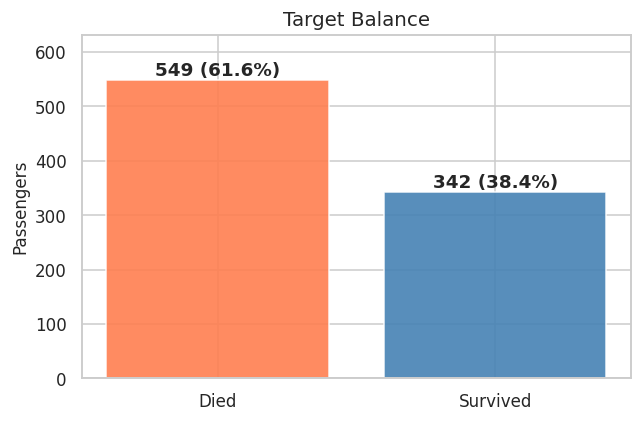

About 38% survived: moderately imbalanced, so we will stratify and look beyond accuracy.


In [ ]:
counts = df_raw["survived"].map({0: "Died", 1: "Survived"}).value_counts()[["Died", "Survived"]]
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(counts.index, counts.values, color=["coral", "steelblue"], edgecolor="white", alpha=0.9)
for i, v in enumerate(counts.values):
    ax.text(i, v + 8, f"{v} ({v / len(df_raw) * 100:.1f}%)", ha="center", fontweight="bold")
ax.set_ylim(0, counts.max() * 1.15); ax.set_ylabel("Passengers"); ax.set_title("Target Balance")
plt.tight_layout(); plt.show()
print(f"About {df_raw['survived'].mean():.0%} survived: moderately imbalanced, so we will stratify and look beyond accuracy.")

---
## Step 5: Remove Leaky and Redundant Columns, Check Duplicates
A **leaky** column contains the answer (or would not exist at prediction time). A **redundant** column repeats another. We prove each suspicion with a check instead of assuming it.

In [ ]:
checks = {
    "alive == survived (text copy of the TARGET)":   (df_raw["alive"].map({"yes": 1, "no": 0}) == df_raw["survived"]).mean(),
    "class == pclass (same information as text)":     (df_raw["class"].astype(str) == df_raw["pclass"].map({1: "First", 2: "Second", 3: "Third"})).mean(),
    "embark_town == embarked (name vs letter)":       (df_raw["embark_town"].fillna("?") == df_raw["embarked"].map(
                                                          {"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"}).fillna("?")).mean(),
    "alone == (sibsp + parch == 0)":                  (df_raw["alone"] == ((df_raw["sibsp"] + df_raw["parch"]) == 0)).mean(),
    "adult_male == (male and age >= 16)":             (df_raw["adult_male"] == ((df_raw["sex"] == "male") & (df_raw["age"] >= 16))).mean(),
}
for name, frac in checks.items():
    print(f"{frac * 100:6.1f}% identical   {name}")

DROP = ["alive", "class", "embark_town", "who", "adult_male", "alone"]
df = df_raw.drop(columns=DROP).copy()
df["deck"] = df["deck"].astype(object)
print(f"\nDropped {DROP}")
print(f"Fully duplicated rows: {df.duplicated().sum()} (no passenger ID or name, so identical rows are plausible and are kept)")
print(f"Remaining columns: {list(df.columns)}")
print("\nNote: adult_male matches our simple rule only 86% of the time, so it relies on an undocumented rule for missing ages.")
print("That hidden imputation is another reason to drop it and handle missing ages ourselves (Step 9).")

 100.0% identical   alive == survived (text copy of the TARGET)
 100.0% identical   class == pclass (same information as text)
 100.0% identical   embark_town == embarked (name vs letter)
 100.0% identical   alone == (sibsp + parch == 0)
  86.1% identical   adult_male == (male and age >= 16)

Dropped ['alive', 'class', 'embark_town', 'who', 'adult_male', 'alone']
Fully duplicated rows: 107 (no passenger ID or name, so identical rows are plausible and are kept)
Remaining columns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'deck']

Note: adult_male matches our simple rule only 86% of the time, so it relies on an undocumented rule for missing ages.
That hidden imputation is another reason to drop it and handle missing ages ourselves (Step 9).


---
## Step 6: Missing-Value Report and Informative Missingness
How much is missing, and does the **fact of being missing** carry information? If so, we keep a flag before imputing.

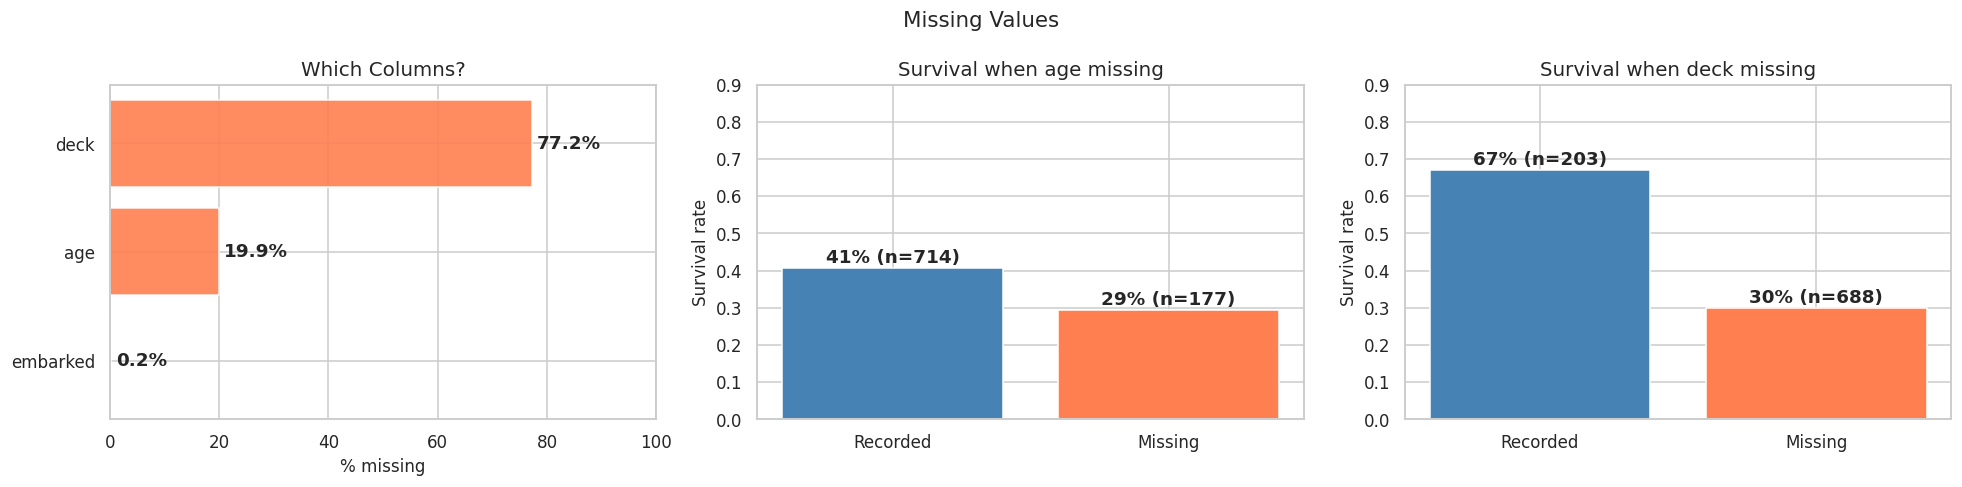

Deck is 77% missing, but a recorded deck mostly means first class: the missingness is a strong signal.
Plan: keep 'has_deck' and 'age_missing' flags, then impute age; do NOT impute the deck letters.


In [ ]:
miss = df.isna().mean().mul(100).round(1)
miss = miss[miss > 0].sort_values()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
fig.suptitle("Missing Values", fontsize=14)
axes[0].barh(miss.index, miss.values, color="coral", edgecolor="white", alpha=0.9)
for i, v in enumerate(miss.values):
    axes[0].text(v + 1, i, f"{v}%", va="center", fontweight="bold")
axes[0].set_xlim(0, 100); axes[0].set_xlabel("% missing"); axes[0].set_title("Which Columns?")

for ax, (col, label) in zip(axes[1:], [("age", "age missing"), ("deck", "deck missing")]):
    flag = df[col].isna()
    g = df.groupby(flag)["survived"].agg(["mean", "size"])
    ax.bar(["Recorded", "Missing"], g["mean"], color=["steelblue", "coral"], edgecolor="white")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m + 0.015, f"{m:.0%} (n={n})", ha="center", fontweight="bold")
    ax.set_ylim(0, 0.9); ax.set_ylabel("Survival rate"); ax.set_title(f"Survival when {label}")
plt.tight_layout(); plt.show()

print("Deck is 77% missing, but a recorded deck mostly means first class: the missingness is a strong signal.")
print("Plan: keep 'has_deck' and 'age_missing' flags, then impute age; do NOT impute the deck letters.")

---
## Step 7: Split into Train and Test (Seal the Test Set)
**Before learning anything**, hold out 20% for the final test, stratified on the target. From here on, every fitted object (imputer, encoder, scaler, selector, model) learns from `X_train` only. We also define the cross-validation schemes used for model comparison.

In [ ]:
X = df.drop(columns="survived")
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

cv      = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)   # 10 folds, main comparisons
cv_fast = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)          # 5 folds, cheaper steps

print(f"Train: {X_train.shape[0]} rows ({y_train.mean():.1%} survived)   Test: {X_test.shape[0]} rows ({y_test.mean():.1%} survived)")
print("The test set is sealed until Step 25.")

Train: 712 rows (38.3% survived)   Test: 179 rows (38.5% survived)
The test set is sealed until Step 25.


---
## Step 8: Feature Engineering
Create columns that expose structure a model cannot easily find alone: combinations, ratios, flags, groupings, interactions. These functions are **stateless** (each row is computed from itself), so applying them to train and test cannot leak.

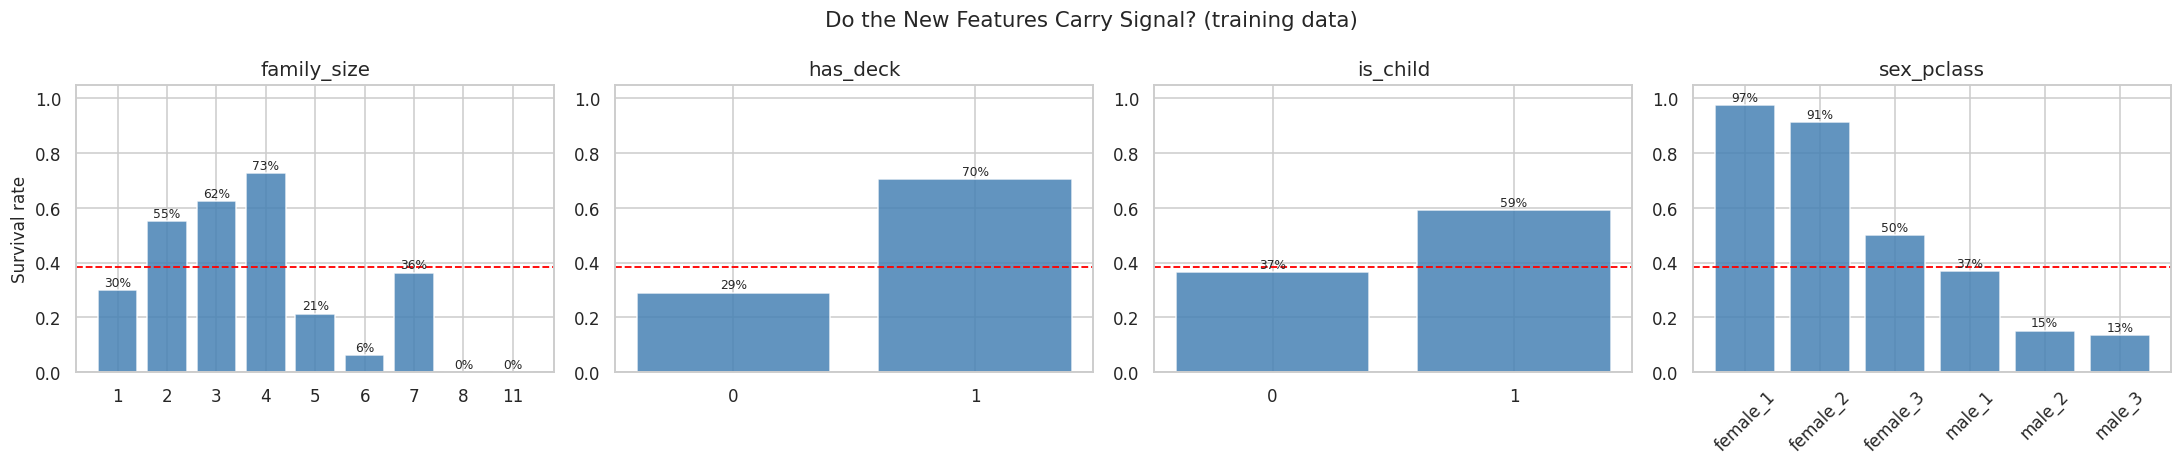

Columns: 8 -> 14.  New: family_size, is_alone, fare_per_person, has_deck, age_missing, is_child, sex_pclass


In [ ]:
def engineer(d):
    d = d.copy()
    d["family_size"]     = d["sibsp"] + d["parch"] + 1
    d["is_alone"]        = (d["family_size"] == 1).astype(int)
    d["fare_per_person"] = d["fare"] / d["family_size"]
    d["has_deck"]        = d["deck"].notna().astype(int)
    d["age_missing"]     = d["age"].isna().astype(int)
    d["is_child"]        = (d["age"] < 12).astype(int)
    d["sex_pclass"]      = d["sex"].astype(str) + "_" + d["pclass"].astype(str)
    return d.drop(columns="deck")

X_train_fe, X_test_fe = engineer(X_train), engineer(X_test)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
fig.suptitle("Do the New Features Carry Signal? (training data)", fontsize=14)
tmp = X_train_fe.assign(survived=y_train)
for ax, col in zip(axes, ["family_size", "has_deck", "is_child", "sex_pclass"]):
    g = tmp.groupby(col)["survived"].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"], color="steelblue", edgecolor="white", alpha=0.85)
    for i, m in enumerate(g["mean"]):
        ax.text(i, m + 0.015, f"{m:.0%}", ha="center", fontsize=8)
    ax.axhline(y_train.mean(), color="red", linestyle="--", linewidth=1.2)
    ax.set_ylim(0, 1.05); ax.set_title(col); ax.tick_params(axis="x", rotation=45 if col == "sex_pclass" else 0)
axes[0].set_ylabel("Survival rate")
plt.tight_layout(); plt.show()

print(f"Columns: {X_train.shape[1]} -> {X_train_fe.shape[1]}.  New: family_size, is_alone, fare_per_person, has_deck, age_missing, is_child, sex_pclass")

---
## Step 9: Impute Missing Values
Replace remaining `NaN`s with values **learned from the training set** (median for numbers, most frequent for categories). The same training medians are then used on the test set. Compare strategies on `age` first.

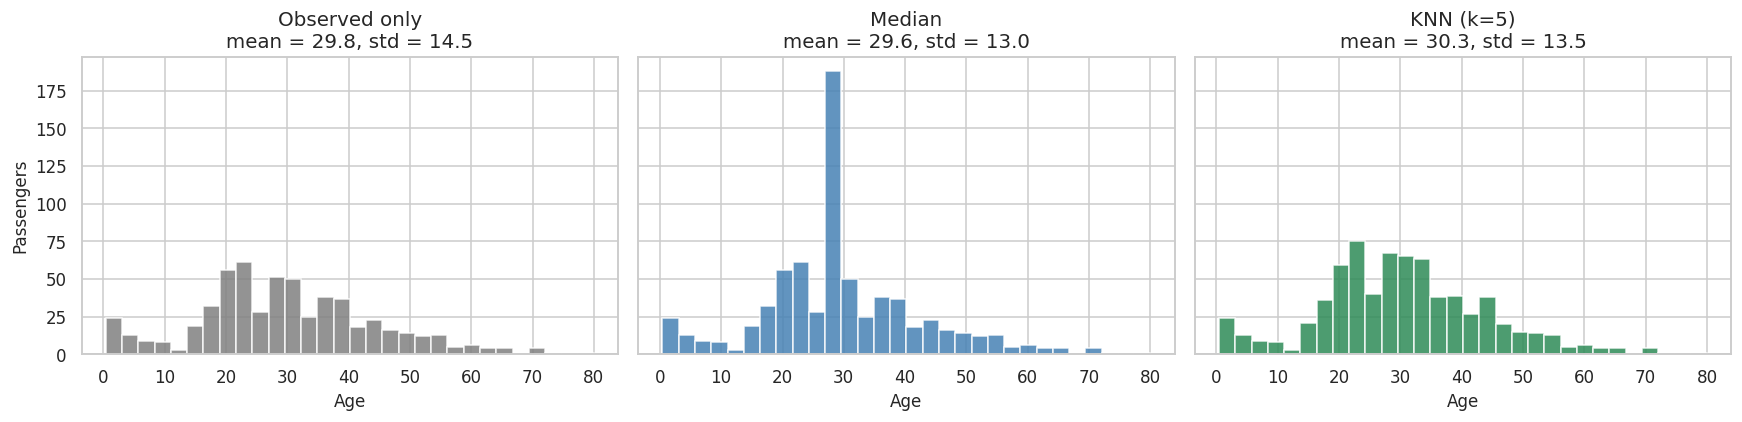

Fill values learned on TRAIN: age median = 28.5, embarked mode = 'S'
NaN remaining  train: 0   test: 0
Median imputation creates a spike at one age; the age_missing flag from Step 8 preserves the fact that the age was unknown.


In [ ]:
from sklearn.impute import KNNImputer
num_ref = ["age", "pclass", "sibsp", "parch", "fare"]
variants = {"Observed only": X_train_fe["age"].dropna().values,
            "Median":        SimpleImputer(strategy="median").fit_transform(X_train_fe[num_ref])[:, 0],
            "KNN (k=5)":     KNNImputer(n_neighbors=5).fit_transform(X_train_fe[num_ref])[:, 0]}

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (name, v), c in zip(axes, variants.items(), ["grey", "steelblue", "seagreen"]):
    ax.hist(v, bins=30, color=c, edgecolor="white", alpha=0.85)
    ax.set_title(f"{name}\nmean = {v.mean():.1f}, std = {v.std():.1f}"); ax.set_xlabel("Age")
axes[0].set_ylabel("Passengers")
plt.tight_layout(); plt.show()

# Learn the fill values on TRAIN, apply to both sets
age_median    = X_train_fe["age"].median()
embarked_mode = X_train_fe["embarked"].mode()[0]

def impute(d):
    d = d.copy()
    d["age"]      = d["age"].fillna(age_median)
    d["embarked"] = d["embarked"].fillna(embarked_mode)
    return d

X_train_i, X_test_i = impute(X_train_fe), impute(X_test_fe)
print(f"Fill values learned on TRAIN: age median = {age_median:.1f}, embarked mode = '{embarked_mode}'")
print(f"NaN remaining  train: {int(X_train_i.isna().sum().sum())}   test: {int(X_test_i.isna().sum().sum())}")
print("Median imputation creates a spike at one age; the age_missing flag from Step 8 preserves the fact that the age was unknown.")

---
## Step 10: Treat Outliers and Skew
Detect outliers with the **IQR rule** (beyond Q1 - 1.5 IQR or Q3 + 1.5 IQR). Real extreme values (a 500-pound first-class fare) should not be deleted; we **transform** skewed columns instead. `log1p` is stateless and handles zeros.

                 outliers   pct  skew
column                               
age                    29   4.1  0.45
fare                   91  12.8  4.64
fare_per_person        76  10.7  7.74
family_size            72  10.1  2.71


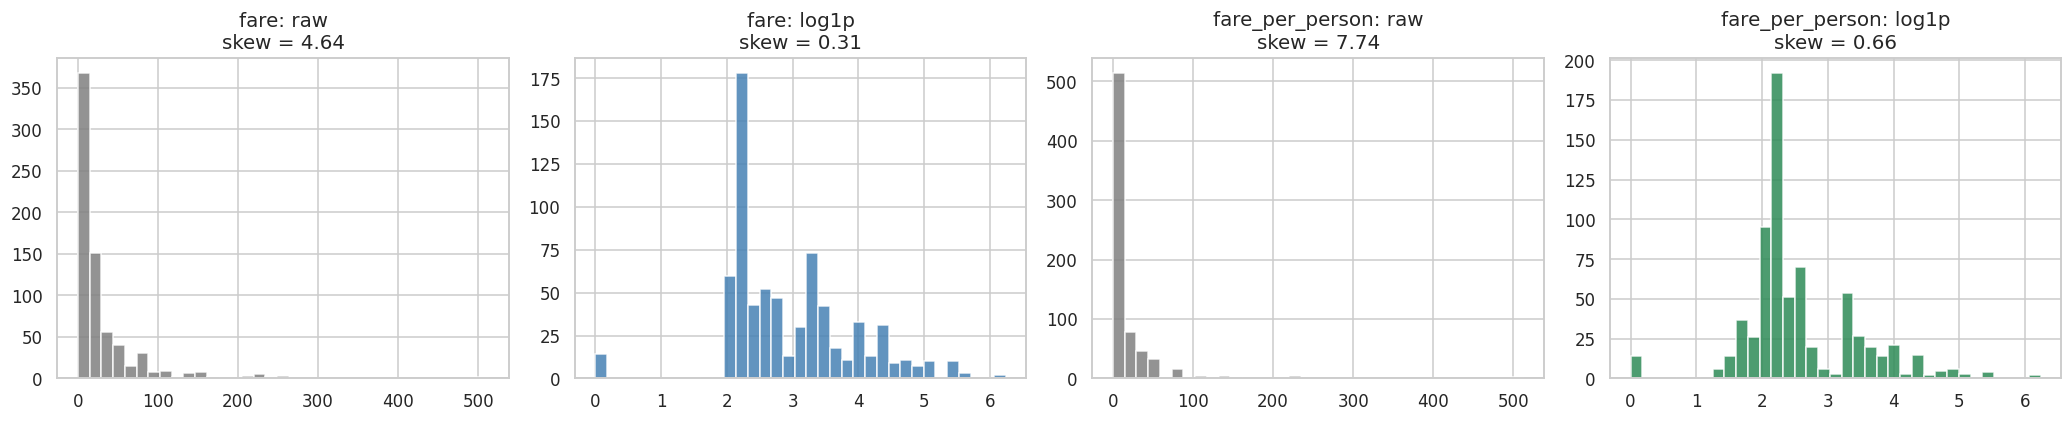

Skew drops sharply after log1p. Other options: clipping at the IQR fence, PowerTransformer, QuantileTransformer, RobustScaler.


In [ ]:
rows = []
for col in ["age", "fare", "fare_per_person", "family_size"]:
    s = X_train_i[col]
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
    rows.append({"column": col, "outliers": n_out, "pct": round(n_out / len(s) * 100, 1), "skew": round(stats.skew(s), 2)})
print(pd.DataFrame(rows).set_index("column").to_string())

skewed = ["fare", "fare_per_person"]
X_train_o, X_test_o = X_train_i.copy(), X_test_i.copy()
for c in skewed:
    X_train_o[c], X_test_o[c] = np.log1p(X_train_i[c]), np.log1p(X_test_i[c])

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, (title, vals, color) in zip(axes, [("fare: raw", X_train_i["fare"], "grey"), ("fare: log1p", X_train_o["fare"], "steelblue"),
                                             ("fare_per_person: raw", X_train_i["fare_per_person"], "grey"),
                                             ("fare_per_person: log1p", X_train_o["fare_per_person"], "seagreen")]):
    ax.hist(vals, bins=35, color=color, edgecolor="white", alpha=0.85)
    ax.set_title(f"{title}\nskew = {stats.skew(vals):.2f}")
plt.tight_layout(); plt.show()
print("Skew drops sharply after log1p. Other options: clipping at the IQR fence, PowerTransformer, QuantileTransformer, RobustScaler.")

---
## Step 11: Encode Categorical Columns
Models need numbers. **One-hot encoding** makes one 0/1 column per category (right for nominal columns). Learn the categories on train; `handle_unknown="ignore"` makes unseen categories all zeros instead of crashing.

In [ ]:
cat_cols = ["sex", "embarked", "sex_pclass"]
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X_train_o[cat_cols])

def encode(d):
    enc = pd.DataFrame(ohe.transform(d[cat_cols]), columns=ohe.get_feature_names_out(cat_cols), index=d.index)
    return pd.concat([d.drop(columns=cat_cols), enc], axis=1)

X_train_e, X_test_e = encode(X_train_o), encode(X_test_o)

print("Learned categories:", {c: list(v) for c, v in zip(cat_cols, ohe.categories_)})
print(f"Columns: {X_train_o.shape[1]} -> {X_train_e.shape[1]} after one-hot encoding")
unseen = pd.DataFrame({"sex": ["female"], "embarked": ["Z"], "sex_pclass": ["female_1"]})
print("Unseen port 'Z' encodes as embarked columns:", ohe.transform(unseen)[0][2:5].astype(int), "(all zeros, no crash)")
X_train_e.head(4)

Learned categories: {'sex': ['female', 'male'], 'embarked': ['C', 'Q', 'S'], 'sex_pclass': ['female_1', 'female_2', 'female_3', 'male_1', 'male_2', 'male_3']}
Columns: 14 -> 22 after one-hot encoding
Unseen port 'Z' encodes as embarked columns: [0 0 0] (all zeros, no crash)


,pclass,age,sibsp,parch,fare,family_size,is_alone,fare_per_person,has_deck,age_missing,...,sex_male,embarked_C,embarked_Q,embarked_S,sex_pclass_female_1,sex_pclass_female_2,sex_pclass_female_3,sex_pclass_male_1,sex_pclass_male_2,sex_pclass_male_3
692,3,28.5,0,0,4.051712,1,1,4.051712,0,1,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
481,2,28.5,0,0,0.000000,1,1,0.000000,0,1,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
527,1,28.5,0,0,5.406181,1,1,5.406181,1,1,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
855,3,18.0,0,1,2.336987,2,0,1.736071,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


---
## Step 12: Scale the Numeric Columns
Distance and gradient models (KNN, SVM, Logistic Regression) need comparable ranges; trees do not. We fit `StandardScaler` on the **training** numbers only. First, a quick demonstration of which models care.

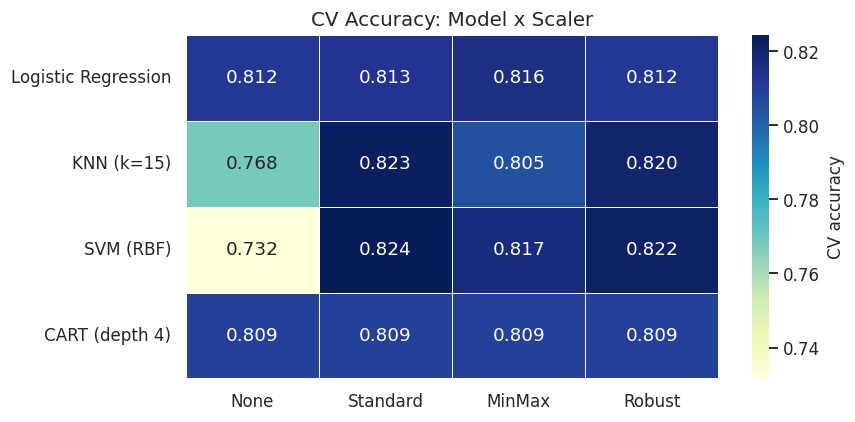

CART accuracy spread across scalers: 0.0000 (trees are scale-invariant)
Train means after scaling ~ 4.1e-16; test means are NOT exactly 0 (that is correct: test uses train statistics).


In [ ]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler
num_cols = ["age", "sibsp", "parch", "fare", "family_size", "fare_per_person", "pclass"]

# Which models care about scaling? Compare on the (unscaled) encoded matrix. The scaler lives INSIDE the pipeline here.
test_models = {"Logistic Regression": LogisticRegression(max_iter=2000), "KNN (k=15)": KNeighborsClassifier(15),
               "SVM (RBF)": SVC(random_state=RANDOM_STATE), "CART (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)}
scalers = {"None": "passthrough", "Standard": StandardScaler(), "MinMax": MinMaxScaler(), "Robust": RobustScaler()}
ct = lambda sc: ColumnTransformer([("s", sc, num_cols)], remainder="passthrough")
grid = pd.DataFrame({sn: {mn: cross_val_score(Pipeline([("sc", ct(sc)), ("m", clone(m))]), X_train_e, y_train,
                                               cv=cv_fast, scoring="accuracy").mean()
                          for mn, m in test_models.items()} for sn, sc in scalers.items()})
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(grid, annot=True, fmt=".3f", cmap="YlGnBu", linewidths=0.5, ax=ax, cbar_kws={"label": "CV accuracy"})
ax.set_title("CV Accuracy: Model x Scaler"); plt.tight_layout(); plt.show()

# Fit the scaler on TRAIN, apply to both
scaler = StandardScaler().fit(X_train_e[num_cols])
X_train_s, X_test_s = X_train_e.copy(), X_test_e.copy()
X_train_s[num_cols] = scaler.transform(X_train_e[num_cols])
X_test_s[num_cols]  = scaler.transform(X_test_e[num_cols])
print(f"CART accuracy spread across scalers: {(grid.loc['CART (depth 4)'].max() - grid.loc['CART (depth 4)'].min()):.4f} (trees are scale-invariant)")
print(f"Train means after scaling ~ {X_train_s[num_cols].mean().abs().max():.2g}; test means are NOT exactly 0 (that is correct: test uses train statistics).")

---
## Step 13: Assemble the Model-Ready Matrices
Final check of the prepared data: same columns in train and test, no `NaN`, all numeric. We also look at how each feature correlates with the target.

Model-ready:  train (712, 22)   test (179, 22)   (all numeric, no NaN)
Features (22): ['pclass', 'age', 'sibsp', 'parch', 'fare', 'family_size', 'is_alone', 'fare_per_person', 'has_deck', 'age_missing', 'is_child', 'sex_female', 'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S', 'sex_pclass_female_1', 'sex_pclass_female_2', 'sex_pclass_female_3', 'sex_pclass_male_1', 'sex_pclass_male_2', 'sex_pclass_male_3']


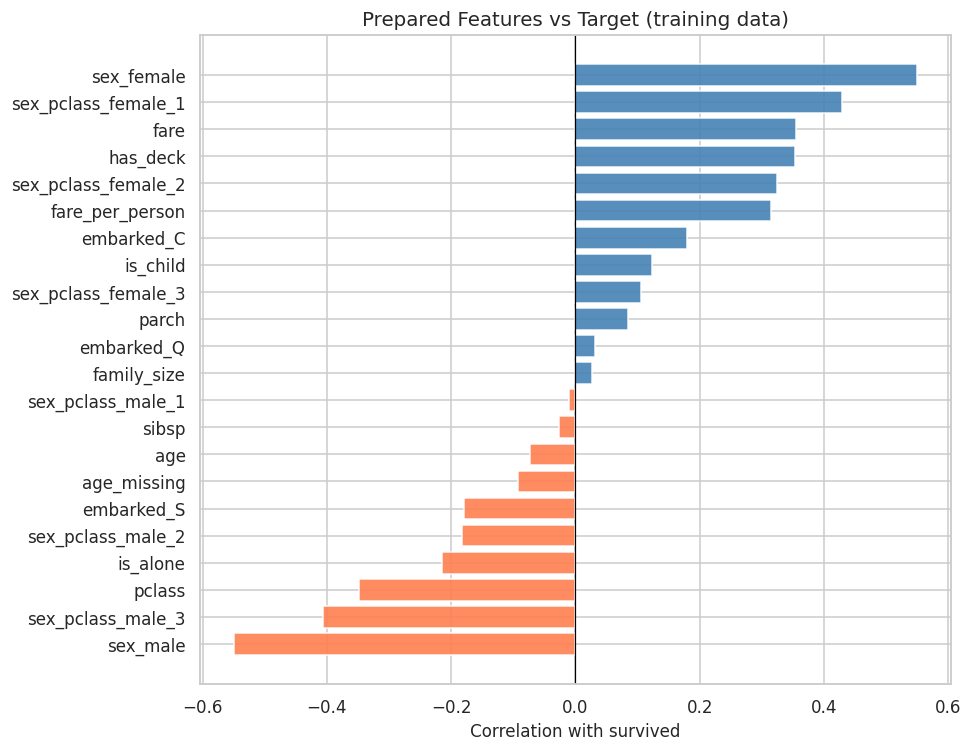

In [ ]:
X_tr, X_te = X_train_s.astype(float), X_test_s.astype(float)
assert list(X_tr.columns) == list(X_te.columns)
assert not X_tr.isna().any().any() and not X_te.isna().any().any()

print(f"Model-ready:  train {X_tr.shape}   test {X_te.shape}   (all numeric, no NaN)")
print(f"Features ({X_tr.shape[1]}): {list(X_tr.columns)}")

corr = pd.concat([X_tr, y_train], axis=1).corr()["survived"].drop("survived").sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(corr.index, corr.values, color=["coral" if v < 0 else "steelblue" for v in corr.values], edgecolor="white", alpha=0.9)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlation with survived"); ax.set_title("Prepared Features vs Target (training data)")
plt.tight_layout(); plt.show()

---
## Step 14: Select Features
Remove noise and redundancy. Look at three views (filter, wrapper, embedded), then **choose k by cross-validation with the selector inside the CV loop**, so selection is never judged on rows it saw.

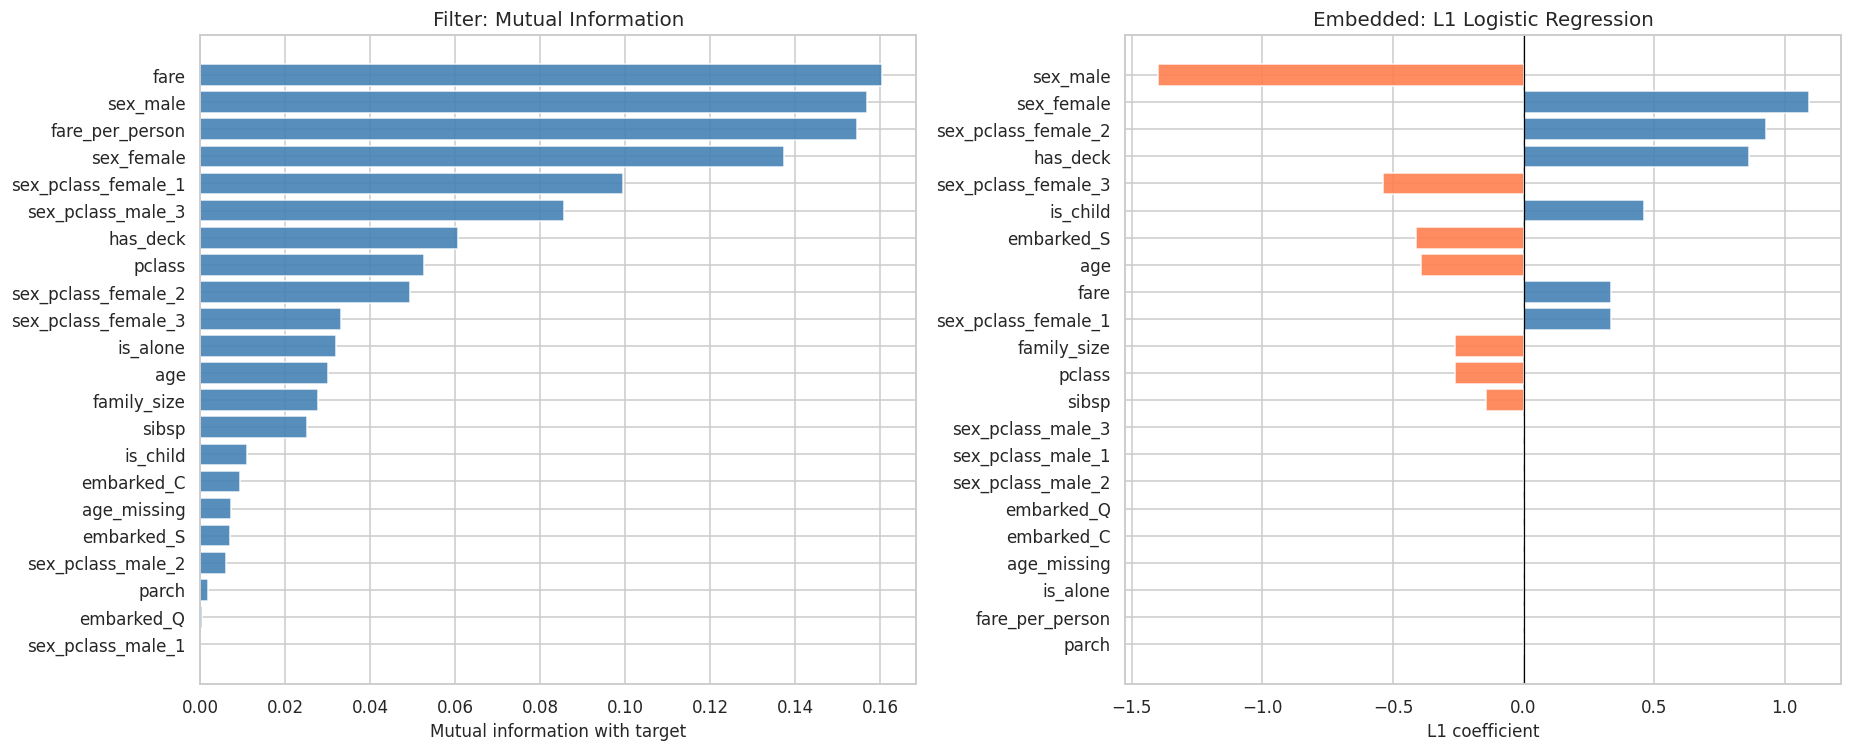

RFE keeps: ['pclass', 'has_deck', 'is_child', 'sex_female', 'sex_male', 'embarked_S', 'sex_pclass_female_1', 'sex_pclass_female_2', 'sex_pclass_female_3', 'sex_pclass_male_1']
L1 sets 9 of 22 coefficients to exactly zero.


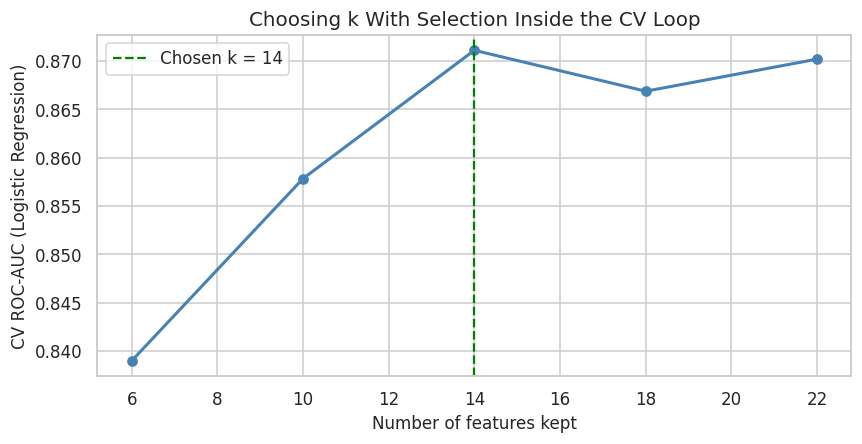

Chosen k = 14 of 22.  Final matrices: train (712, 14), test (179, 14)


In [ ]:
n_feat = X_tr.shape[1]
mi = pd.Series(mutual_info_classif(X_tr, y_train, random_state=RANDOM_STATE), index=X_tr.columns).sort_values()
rfe = RFE(LogisticRegression(max_iter=2000), n_features_to_select=10).fit(X_tr, y_train)
l1 = LogisticRegression(penalty="l1", solver="liblinear", C=0.3).fit(X_tr, y_train)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
axes[0].barh(mi.index, mi.values, color="steelblue", edgecolor="white", alpha=0.9)
axes[0].set_xlabel("Mutual information with target"); axes[0].set_title("Filter: Mutual Information")
l1c = pd.Series(l1.coef_[0], index=X_tr.columns).reindex(X_tr.columns[np.argsort(np.abs(l1.coef_[0]))])
axes[1].barh(l1c.index, l1c.values, color=["coral" if v < 0 else "steelblue" for v in l1c.values], edgecolor="white", alpha=0.9)
axes[1].axvline(0, color="black", linewidth=0.8); axes[1].set_xlabel("L1 coefficient"); axes[1].set_title("Embedded: L1 Logistic Regression")
plt.tight_layout(); plt.show()
print(f"RFE keeps: {list(X_tr.columns[rfe.support_])}")
print(f"L1 sets {int((l1.coef_[0] == 0).sum())} of {n_feat} coefficients to exactly zero.")

# Choose k with the selector INSIDE cross-validation
ks = [6, 10, 14, 18, n_feat]
sel_scores = [cross_val_score(Pipeline([("sel", SelectKBest(partial(mutual_info_classif, random_state=RANDOM_STATE), k=k)),
                                         ("lr", LogisticRegression(max_iter=2000))]),
                              X_tr, y_train, cv=cv_fast, scoring="roc_auc").mean() for k in ks]
sel_k = ks[int(np.argmax(sel_scores))]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(ks, sel_scores, "o-", color="steelblue", linewidth=2)
ax.axvline(sel_k, color="green", linestyle="--", label=f"Chosen k = {sel_k}")
ax.set_xlabel("Number of features kept"); ax.set_ylabel("CV ROC-AUC (Logistic Regression)")
ax.set_title("Choosing k With Selection Inside the CV Loop"); ax.legend()
plt.tight_layout(); plt.show()

selector = SelectKBest(partial(mutual_info_classif, random_state=RANDOM_STATE), k=sel_k).fit(X_tr, y_train)
keep = X_tr.columns[selector.get_support()]
X_tr_sel, X_te_sel = X_tr[keep], X_te[keep]
print(f"Chosen k = {sel_k} of {n_feat}.  Final matrices: train {X_tr_sel.shape}, test {X_te_sel.shape}")
if sel_k == n_feat:
    print("The full set wins here, so nothing is removed. Selection can help, but test it instead of assuming it.")

---
## Step 15: Baseline Model
Every real model must beat a trivial one. The **majority-class** baseline ignores all features; its accuracy is the floor, and its ROC-AUC of 0.5 is chance.

In [ ]:
base = DummyClassifier(strategy="most_frequent").fit(X_tr_sel, y_train)
r = cross_validate(base, X_tr_sel, y_train, cv=cv, scoring={"acc": "accuracy", "auc": "roc_auc"})
print(f"Baseline (always 'Died'):  CV accuracy = {r['test_acc'].mean():.3f}   CV ROC-AUC = {r['test_auc'].mean():.3f}")
print(f"Recall on survivors = 0: it never finds a single survivor, even though accuracy looks respectable.")
print("Any useful model must beat this accuracy AND show real ranking ability (AUC well above 0.5).")

Baseline (always 'Died'):  CV accuracy = 0.617   CV ROC-AUC = 0.500
Recall on survivors = 0: it never finds a single survivor, even though accuracy looks respectable.
Any useful model must beat this accuracy AND show real ranking ability (AUC well above 0.5).


---
## Step 16: Train and Compare Single Models
Twelve algorithms, the **same prepared data, the same 10 CV folds, the same metrics**. We keep every fold's ROC-AUC so we can test differences later. `evaluate()` is reused in the following steps.

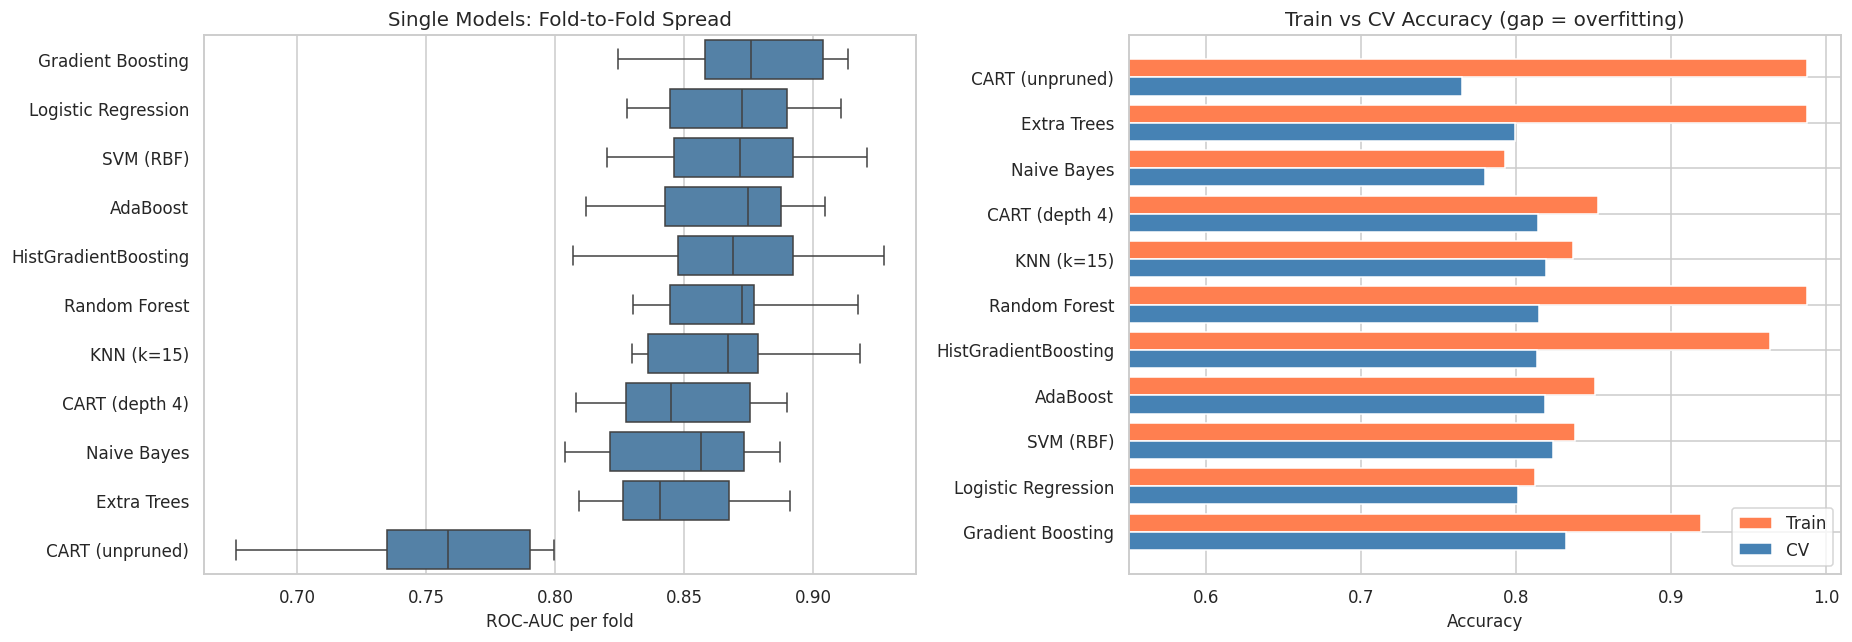

                      train_acc  cv_acc   cv_f1  cv_auc  cv_auc_std   fit_s
Gradient Boosting        0.9196  0.8322  0.7707  0.8770      0.0284  0.0943
Logistic Regression      0.8125  0.8012  0.7172  0.8695      0.0273  0.0058
SVM (RBF)                0.8380  0.8237  0.7451  0.8694      0.0318  0.0272
AdaBoost                 0.8509  0.8188  0.7528  0.8663      0.0296  0.2208
HistGradientBoosting     0.9640  0.8132  0.7494  0.8660      0.0368  0.0782
Random Forest            0.9877  0.8146  0.7573  0.8659      0.0243  0.3229
KNN (k=15)               0.8366  0.8195  0.7481  0.8650      0.0308  0.0022
CART (depth 4)           0.8527  0.8139  0.7432  0.8496      0.0292  0.0027
Naive Bayes              0.7930  0.7802  0.7047  0.8488      0.0288  0.0019
Extra Trees              0.9877  0.7992  0.7378  0.8453      0.0257  0.2443
CART (unpruned)          0.9877  0.7647  0.6993  0.7539      0.0397  0.0033


In [ ]:
results, fold_auc = {}, {}

def evaluate(name, est, X=None, yv=None):
    """Repeated stratified CV; stores summary and per-fold AUC (when the model has probabilities)."""
    X  = X_tr_sel if X is None else X
    yv = y_train if yv is None else yv
    sc = {"acc": "accuracy", "f1": "f1"}
    if hasattr(est, "predict_proba"):
        sc["auc"] = "roc_auc"
    r = cross_validate(est, X, yv, cv=cv, scoring=sc, return_train_score=True)
    if "test_auc" in r:
        fold_auc[name] = r["test_auc"]
    results[name] = {"train_acc": r["train_acc"].mean(), "cv_acc": r["test_acc"].mean(), "cv_f1": r["test_f1"].mean(),
                     "cv_auc": r["test_auc"].mean() if "test_auc" in r else np.nan,
                     "cv_auc_std": r["test_auc"].std() if "test_auc" in r else np.nan,
                     "fit_s": r["fit_time"].mean()}

zoo = {
    "Logistic Regression":  LogisticRegression(max_iter=2000),
    "KNN (k=15)":           KNeighborsClassifier(15),
    "Naive Bayes":          GaussianNB(),
    "SVM (RBF)":            SVC(probability=True, random_state=RANDOM_STATE),
    "CART (depth 4)":       DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "CART (unpruned)":      DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest":        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "Extra Trees":          ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "AdaBoost":             AdaBoostClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "Gradient Boosting":    GradientBoostingClassifier(random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
for name, est in zoo.items():
    evaluate(name, est)

single_df = pd.DataFrame(results).T.sort_values("cv_auc", ascending=False)
order = list(single_df.index)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.boxplot(data=pd.DataFrame(fold_auc)[order], orient="h", color="steelblue", ax=axes[0])
axes[0].set_xlabel("ROC-AUC per fold"); axes[0].set_title("Single Models: Fold-to-Fold Spread")
yp = np.arange(len(order))
axes[1].barh(yp + 0.2, single_df["train_acc"], 0.4, color="coral", edgecolor="white", label="Train")
axes[1].barh(yp - 0.2, single_df["cv_acc"], 0.4, color="steelblue", edgecolor="white", label="CV")
axes[1].set_yticks(yp); axes[1].set_yticklabels(order); axes[1].set_xlim(0.55, 1.01)
axes[1].set_xlabel("Accuracy"); axes[1].set_title("Train vs CV Accuracy (gap = overfitting)"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()
print(single_df.round(4).to_string())

---
## Step 17: CART: Read, Overfit, Prune
**CART** splits on the feature and threshold that most reduce impurity (Gini or entropy). A deep tree memorises noise (high variance). Control it with `max_depth`, `min_samples_leaf`, or **cost-complexity pruning** (`ccp_alpha`: cut branches whose accuracy gain per leaf is below alpha).

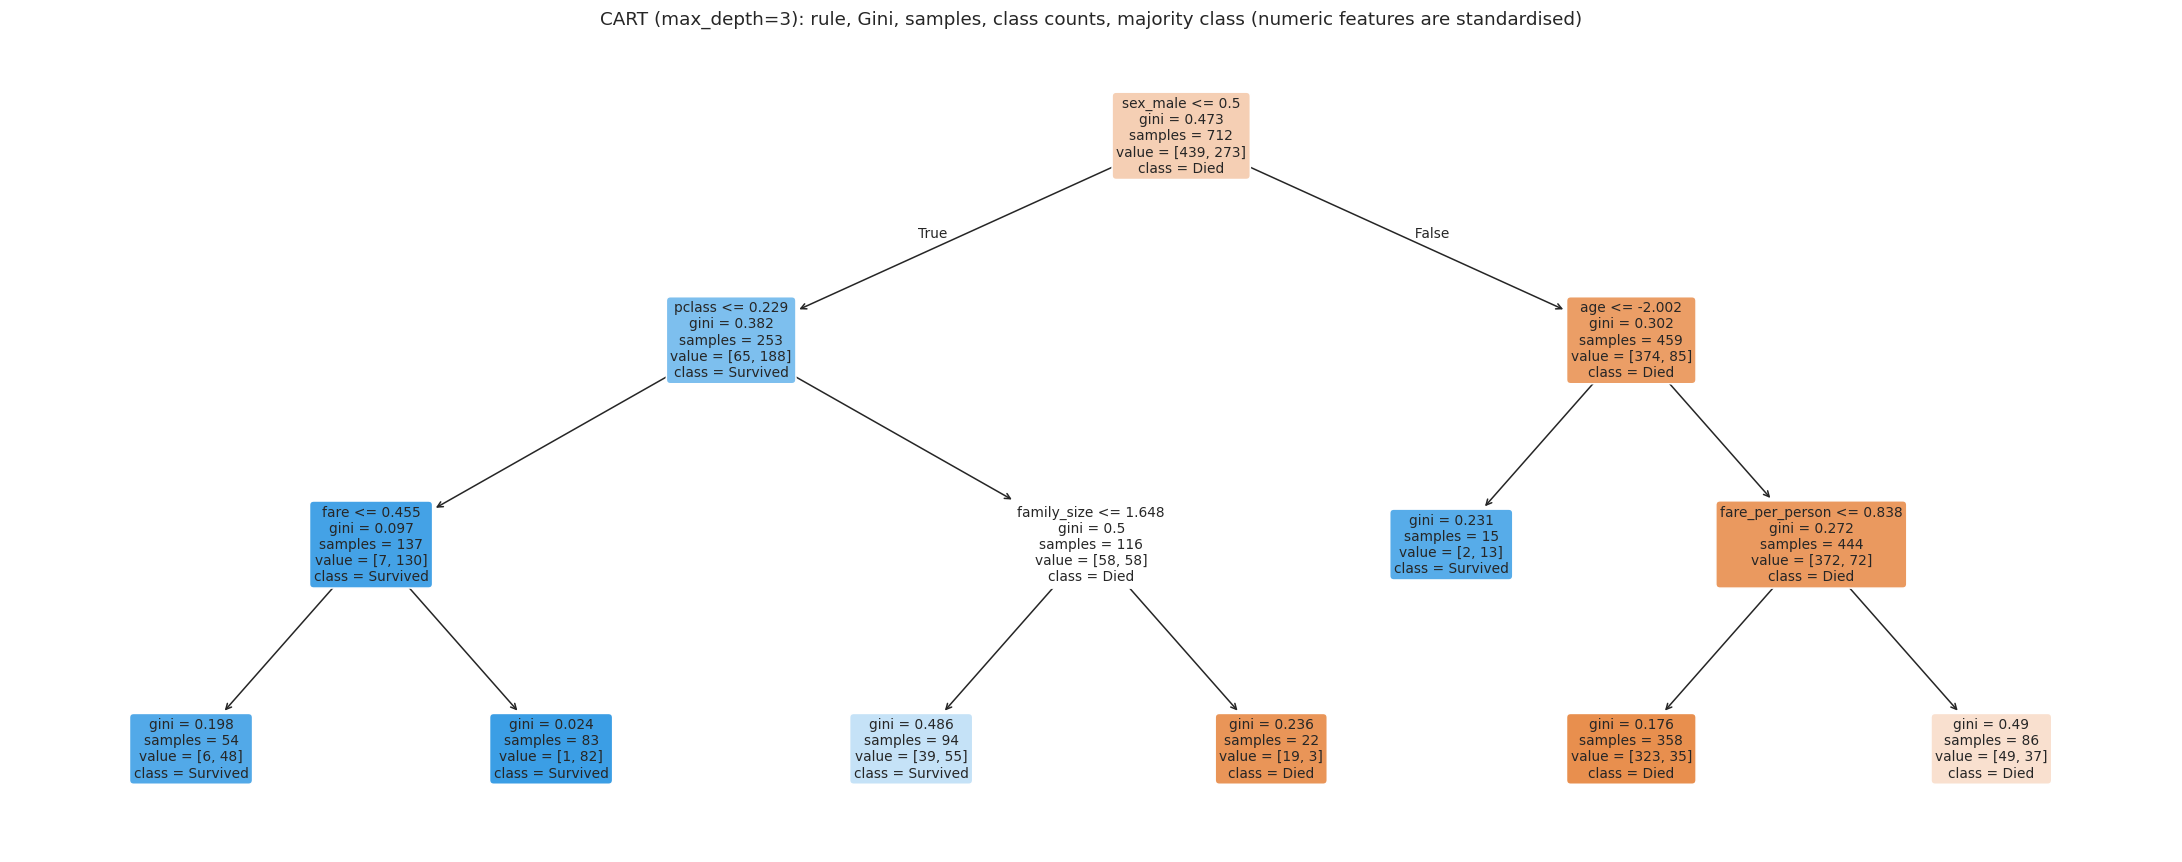

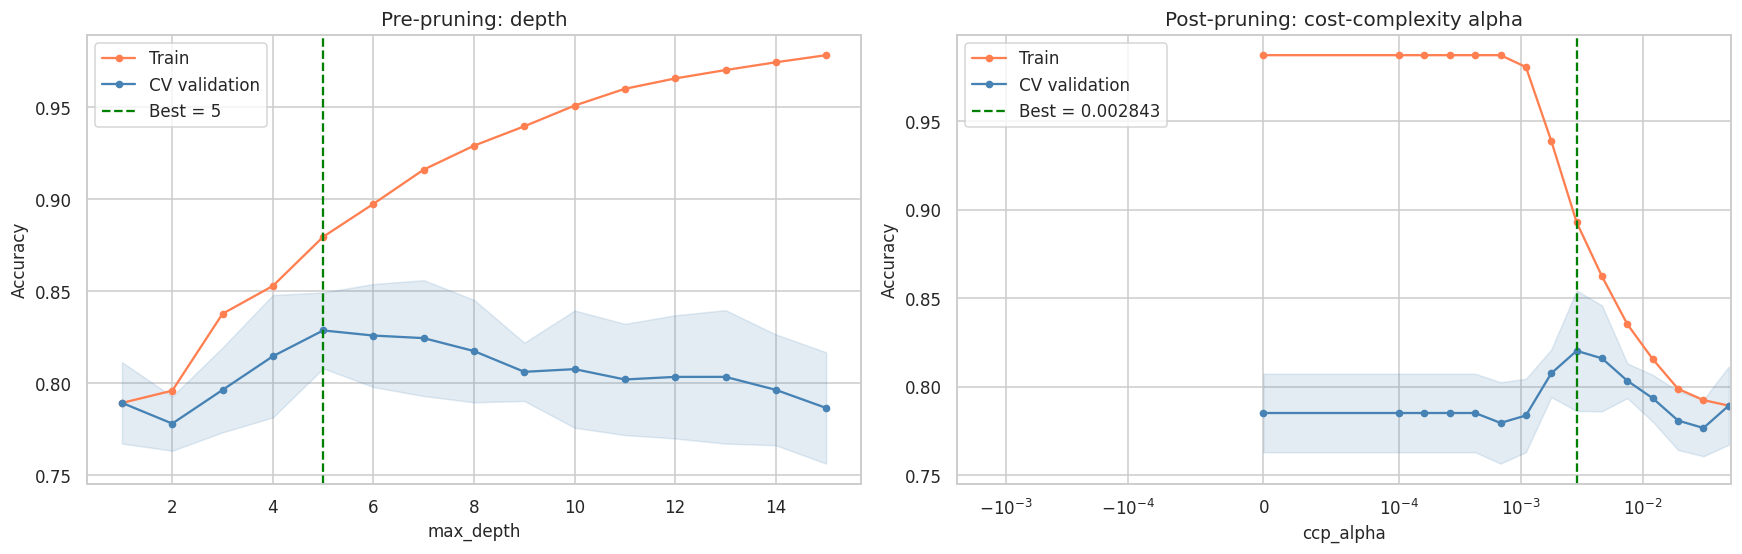

Best depth = 5; best ccp_alpha = 0.002843
Unpruned (depth 15): train accuracy 0.978 vs CV accuracy 0.787: classic overfitting.
|--- sex_male <= 0.50
|   |--- pclass <= 0.23
|   |   |--- fare <= 0.46
|   |   |   |--- class: 1
|   |   |--- fare >  0.46
|   |   |   |--- class: 1
|   |--- pclass >  0.23
|   |   |--- family_size <= 1.65
|   |   |   |--- class: 1
|   |   |--- family_size >  1.65
|   |   |   |--- class: 0
|--- sex_male >  0.50
|   |--- age <= -2.00
|   |   |--- class: 1
|   |--- age >  -2.00
|   |   |--- fare_per_person <= 0.84
|   |   |   |--- class: 0
|   |   |--- fare_per_person >  0.84
|   |   |   |--- class: 0



In [ ]:
tree3 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=RANDOM_STATE).fit(X_tr_sel, y_train)
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(tree3, feature_names=list(X_tr_sel.columns), class_names=["Died", "Survived"], filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("CART (max_depth=3): rule, Gini, samples, class counts, majority class (numeric features are standardised)", fontsize=12)
plt.tight_layout(); plt.show()

depths = np.arange(1, 16)
tr_d, va_d = validation_curve(DecisionTreeClassifier(random_state=RANDOM_STATE), X_tr_sel, y_train, param_name="max_depth",
                              param_range=depths, cv=cv_fast, scoring="accuracy")
alphas = np.concatenate([[0], np.logspace(-4, -1.3, 14)])
tr_a, va_a = validation_curve(DecisionTreeClassifier(random_state=RANDOM_STATE), X_tr_sel, y_train, param_name="ccp_alpha",
                              param_range=alphas, cv=cv_fast, scoring="accuracy")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, rg, tr, va, xl, title, logx in [(axes[0], depths, tr_d, va_d, "max_depth", "Pre-pruning: depth", False),
                                          (axes[1], alphas, tr_a, va_a, "ccp_alpha", "Post-pruning: cost-complexity alpha", True)]:
    ax.plot(rg, tr.mean(axis=1), "o-", color="coral", label="Train", markersize=4)
    ax.plot(rg, va.mean(axis=1), "o-", color="steelblue", label="CV validation", markersize=4)
    ax.fill_between(rg, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), color="steelblue", alpha=0.15)
    best = rg[int(np.argmax(va.mean(axis=1)))]
    ax.axvline(best, color="green", linestyle="--", label=f"Best = {best:.4g}")
    if logx: ax.set_xscale("symlog", linthresh=1e-4)
    ax.set_xlabel(xl); ax.set_ylabel("Accuracy"); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()
print(f"Best depth = {int(depths[int(np.argmax(va_d.mean(axis=1)))])}; best ccp_alpha = {alphas[int(np.argmax(va_a.mean(axis=1)))]:.4g}")
print(f"Unpruned (depth 15): train accuracy {tr_d.mean(axis=1)[-1]:.3f} vs CV accuracy {va_d.mean(axis=1)[-1]:.3f}: classic overfitting.")
print(export_text(tree3, feature_names=list(X_tr_sel.columns), max_depth=3))

---
## Step 18: Ensembles I: Bagging and Random Forest
**Bagging** trains many trees on bootstrap samples and averages them, cancelling the variance of a single unstable tree. **Random Forest** also randomises the features each split considers, making the trees more different.

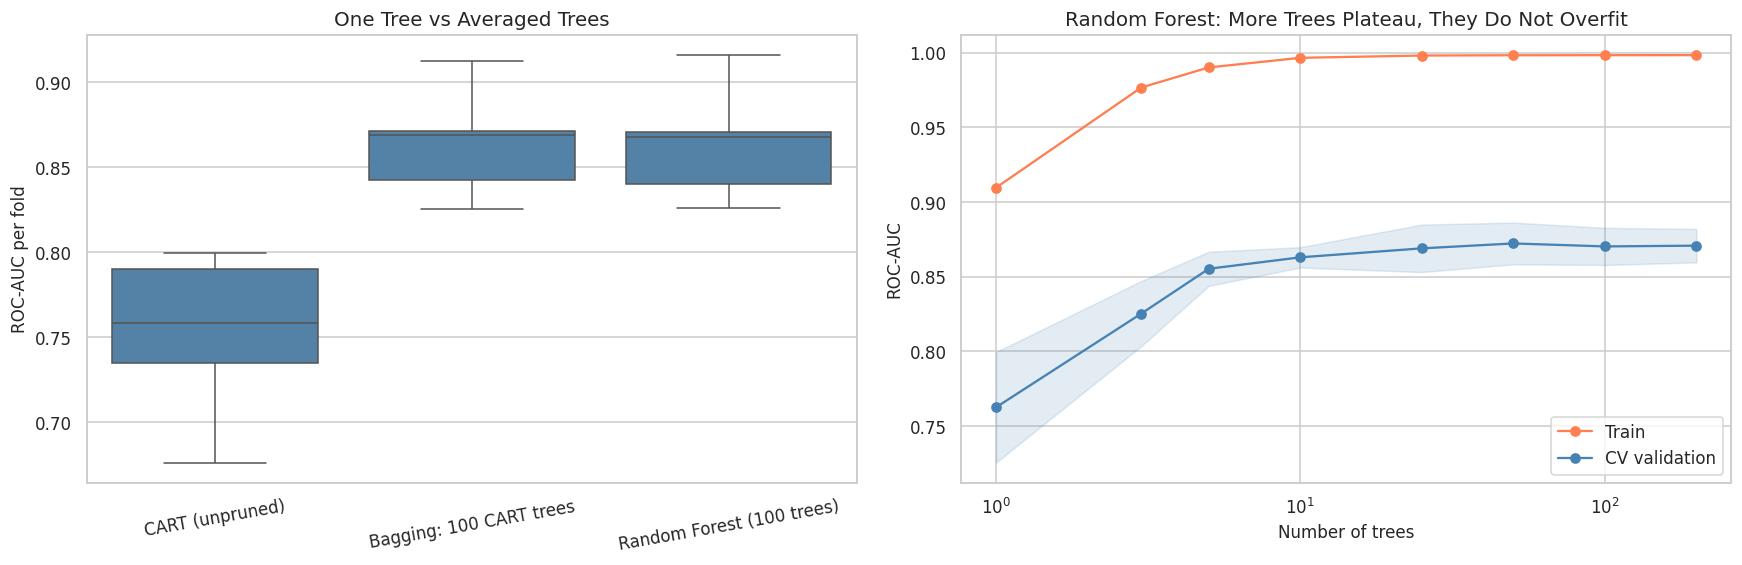

CART (unpruned)              AUC = 0.7539 ± 0.0397
Bagging: 100 CART trees      AUC = 0.8624 ± 0.0261
Random Forest (100 trees)    AUC = 0.8634 ± 0.0257


In [ ]:
bag_models = {
    "CART (unpruned)":           DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Bagging: 100 CART trees":   BaggingClassifier(DecisionTreeClassifier(random_state=RANDOM_STATE), n_estimators=100, random_state=RANDOM_STATE),
    "Random Forest (100 trees)": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
}
bag_auc = {n: cross_val_score(m, X_tr_sel, y_train, cv=cv, scoring="roc_auc") for n, m in bag_models.items()}
fold_auc["Bagging: 100 CART trees"] = bag_auc["Bagging: 100 CART trees"]
evaluate("Bagging: 100 CART trees", bag_models["Bagging: 100 CART trees"])

n_trees = [1, 3, 5, 10, 25, 50, 100, 200]
tr_n, va_n = validation_curve(RandomForestClassifier(random_state=RANDOM_STATE), X_tr_sel, y_train, param_name="n_estimators",
                              param_range=n_trees, cv=cv_fast, scoring="roc_auc")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.3))
sns.boxplot(data=pd.DataFrame(bag_auc), color="steelblue", ax=axes[0])
axes[0].set_ylabel("ROC-AUC per fold"); axes[0].set_title("One Tree vs Averaged Trees"); axes[0].tick_params(axis="x", rotation=10)
axes[1].plot(n_trees, tr_n.mean(axis=1), "o-", color="coral", label="Train")
axes[1].plot(n_trees, va_n.mean(axis=1), "o-", color="steelblue", label="CV validation")
axes[1].fill_between(n_trees, va_n.mean(axis=1) - va_n.std(axis=1), va_n.mean(axis=1) + va_n.std(axis=1), color="steelblue", alpha=0.15)
axes[1].set_xscale("log"); axes[1].set_xlabel("Number of trees"); axes[1].set_ylabel("ROC-AUC")
axes[1].set_title("Random Forest: More Trees Plateau, They Do Not Overfit"); axes[1].legend()
plt.tight_layout(); plt.show()
for n, v in bag_auc.items():
    print(f"{n:28s} AUC = {v.mean():.4f} ± {v.std():.4f}")

---
## Step 19: Ensembles II: Boosting
**Boosting** adds small trees one at a time, each fitted to the errors of the ensemble so far. `learning_rate` (shrinkage) and the number of trees interact: smaller rates need more trees but generalise better. **Early stopping** picks the number of trees where validation performance peaks.

learning_rate = 0.5   best validation accuracy 0.8371 at 6 trees


learning_rate = 0.1   best validation accuracy 0.8371 at 26 trees


learning_rate = 0.02  best validation accuracy 0.8315 at 101 trees


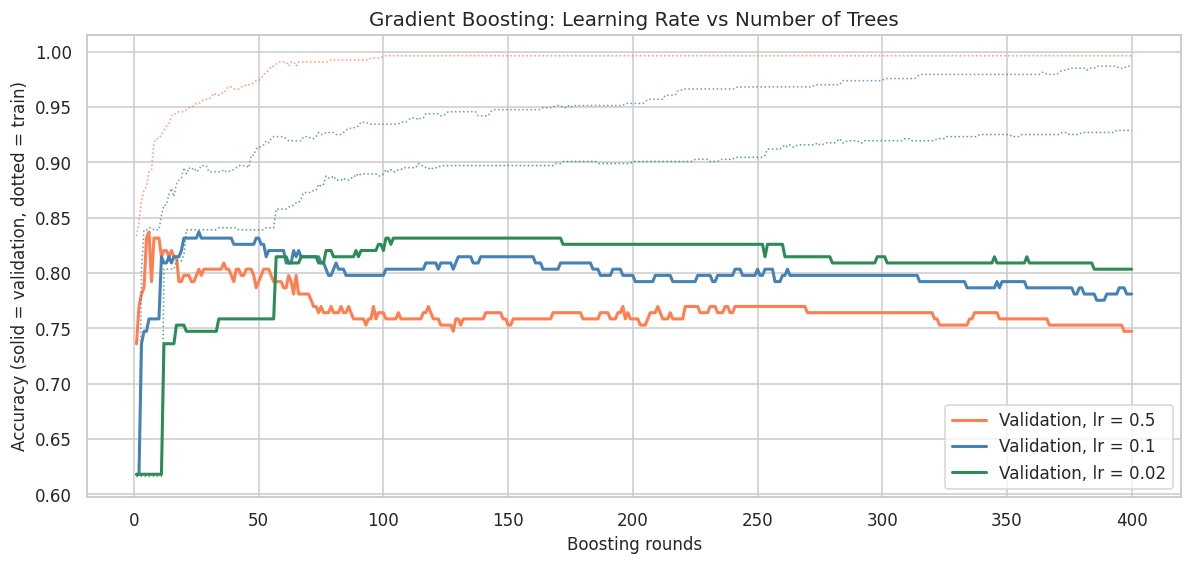


HistGradientBoosting early stopping chose 47 of 1000 possible trees.
Train keeps rising while validation flattens or falls: that gap is overfitting.
AdaBoost               CV AUC = 0.8663
Gradient Boosting      CV AUC = 0.8770
HistGradientBoosting   CV AUC = 0.8660


In [ ]:
X_a, X_v, y_a, y_v = train_test_split(X_tr_sel, y_train, test_size=0.25, stratify=y_train, random_state=1)

fig, ax = plt.subplots(figsize=(11, 5.3))
for lr, color in [(0.5, "coral"), (0.1, "steelblue"), (0.02, "seagreen")]:
    gb = GradientBoostingClassifier(n_estimators=400, learning_rate=lr, max_depth=3, random_state=RANDOM_STATE).fit(X_a, y_a)
    tr = [accuracy_score(y_a, p) for p in gb.staged_predict(X_a)]
    va = [accuracy_score(y_v, p) for p in gb.staged_predict(X_v)]
    ax.plot(range(1, 401), va, color=color, linewidth=2, label=f"Validation, lr = {lr}")
    ax.plot(range(1, 401), tr, color=color, linewidth=1, linestyle=":", alpha=0.8)
    print(f"learning_rate = {lr:<5} best validation accuracy {max(va):.4f} at {int(np.argmax(va)) + 1} trees")
ax.set_xlabel("Boosting rounds"); ax.set_ylabel("Accuracy (solid = validation, dotted = train)")
ax.set_title("Gradient Boosting: Learning Rate vs Number of Trees"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

hgb_es = HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, validation_fraction=0.15, n_iter_no_change=20,
                                        random_state=RANDOM_STATE).fit(X_a, y_a)
print(f"\nHistGradientBoosting early stopping chose {hgb_es.n_iter_} of 1000 possible trees.")
print("Train keeps rising while validation flattens or falls: that gap is overfitting.")
for name in ["AdaBoost", "Gradient Boosting", "HistGradientBoosting"]:
    print(f"{name:22s} CV AUC = {results[name]['cv_auc']:.4f}")

---
## Step 20: Ensembles III: Voting
**Voting** combines **different model types** trained on the same data. *Hard* voting takes the majority class; *soft* voting averages predicted probabilities (usually better, and it keeps probabilities for ROC).

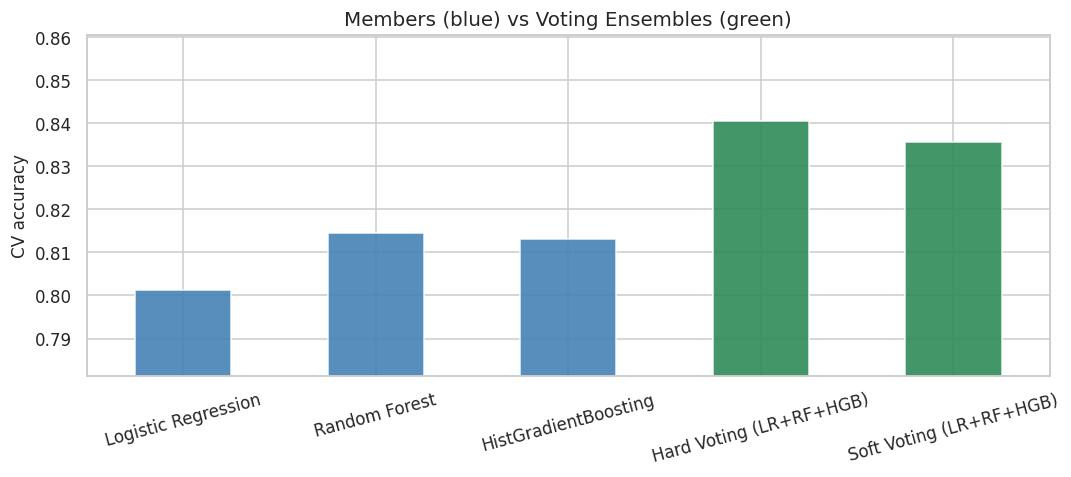

                         cv_acc   cv_f1  cv_auc
Logistic Regression      0.8012  0.7172  0.8695
Random Forest            0.8146  0.7573  0.8659
HistGradientBoosting     0.8132  0.7494  0.8660
Hard Voting (LR+RF+HGB)  0.8406  0.7807     NaN
Soft Voting (LR+RF+HGB)  0.8357  0.7713  0.8863

Hard voting has no probabilities, so no ROC-AUC. Soft voting needs members that output probabilities.


In [ ]:
def base_models():
    return [("lr",  LogisticRegression(max_iter=2000)),
            ("rf",  RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=RANDOM_STATE)),
            ("hgb", HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=150, random_state=RANDOM_STATE))]

hard_vote = VotingClassifier(base_models(), voting="hard")
soft_vote = VotingClassifier(base_models(), voting="soft")
evaluate("Hard Voting (LR+RF+HGB)", hard_vote)
evaluate("Soft Voting (LR+RF+HGB)", soft_vote)

vote_df = pd.DataFrame(results).T.loc[["Logistic Regression", "Random Forest", "HistGradientBoosting",
                                       "Hard Voting (LR+RF+HGB)", "Soft Voting (LR+RF+HGB)"], ["cv_acc", "cv_f1", "cv_auc"]]
fig, ax = plt.subplots(figsize=(10, 4.5))
vote_df["cv_acc"].plot(kind="bar", ax=ax, color=["steelblue"] * 3 + ["seagreen"] * 2, edgecolor="white", alpha=0.9)
ax.set_ylim(vote_df["cv_acc"].min() - 0.02, vote_df["cv_acc"].max() + 0.02)
ax.set_ylabel("CV accuracy"); ax.set_title("Members (blue) vs Voting Ensembles (green)"); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()
print(vote_df.round(4).to_string())
print("\nHard voting has no probabilities, so no ROC-AUC. Soft voting needs members that output probabilities.")

---
## Step 21: Ensembles IV: Stacking
**Stacking** trains a **meta-learner** on the **out-of-fold predictions** of several base models, learning how much to trust each one. It is the most flexible (and most expensive) ensemble.

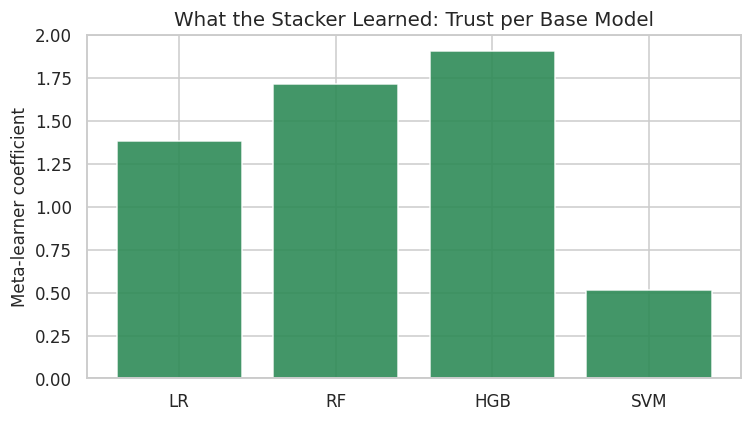

Stacking CV AUC = 0.8862   CV accuracy = 0.8357


In [ ]:
stack = StackingClassifier(estimators=base_models() + [("svm", SVC(probability=True, random_state=RANDOM_STATE))],
                           final_estimator=LogisticRegression(max_iter=2000), cv=5, stack_method="predict_proba")
evaluate("Stacking (LR+RF+HGB+SVM)", stack)

stack_fit = clone(stack).fit(X_tr_sel, y_train)
meta_w = pd.Series(stack_fit.final_estimator_.coef_[0], index=["LR", "RF", "HGB", "SVM"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(meta_w.index, meta_w.values, color="seagreen", edgecolor="white", alpha=0.9)
ax.axhline(0, color="black", linewidth=0.8); ax.set_ylabel("Meta-learner coefficient")
ax.set_title("What the Stacker Learned: Trust per Base Model")
plt.tight_layout(); plt.show()
print(f"Stacking CV AUC = {results['Stacking (LR+RF+HGB+SVM)']['cv_auc']:.4f}   CV accuracy = {results['Stacking (LR+RF+HGB+SVM)']['cv_acc']:.4f}")

---
## Step 22: Compare Everything and Test the Differences
One league table for all models and ensembles, a **paired Wilcoxon test** on the shared folds, and a look at **why ensembles help (or do not)**: the diversity of out-of-fold predictions.

                          train_acc  cv_acc   cv_f1  cv_auc  cv_auc_std   fit_s
Soft Voting (LR+RF+HGB)      0.8873  0.8357  0.7713  0.8863      0.0280  0.2370
Stacking (LR+RF+HGB+SVM)     0.8822  0.8357  0.7726  0.8862      0.0280  1.6044
Gradient Boosting            0.9196  0.8322  0.7707  0.8770      0.0284  0.0943
Logistic Regression          0.8125  0.8012  0.7172  0.8695      0.0273  0.0058
SVM (RBF)                    0.8380  0.8237  0.7451  0.8694      0.0318  0.0272
AdaBoost                     0.8509  0.8188  0.7528  0.8663      0.0296  0.2208
HistGradientBoosting         0.9640  0.8132  0.7494  0.8660      0.0368  0.0782
Random Forest                0.9877  0.8146  0.7573  0.8659      0.0243  0.3229
KNN (k=15)                   0.8366  0.8195  0.7481  0.8650      0.0308  0.0022
Bagging: 100 CART trees      0.9877  0.8104  0.7513  0.8624      0.0261  0.1552
CART (depth 4)               0.8527  0.8139  0.7432  0.8496      0.0292  0.0027
Naive Bayes                  0.7930  0.7

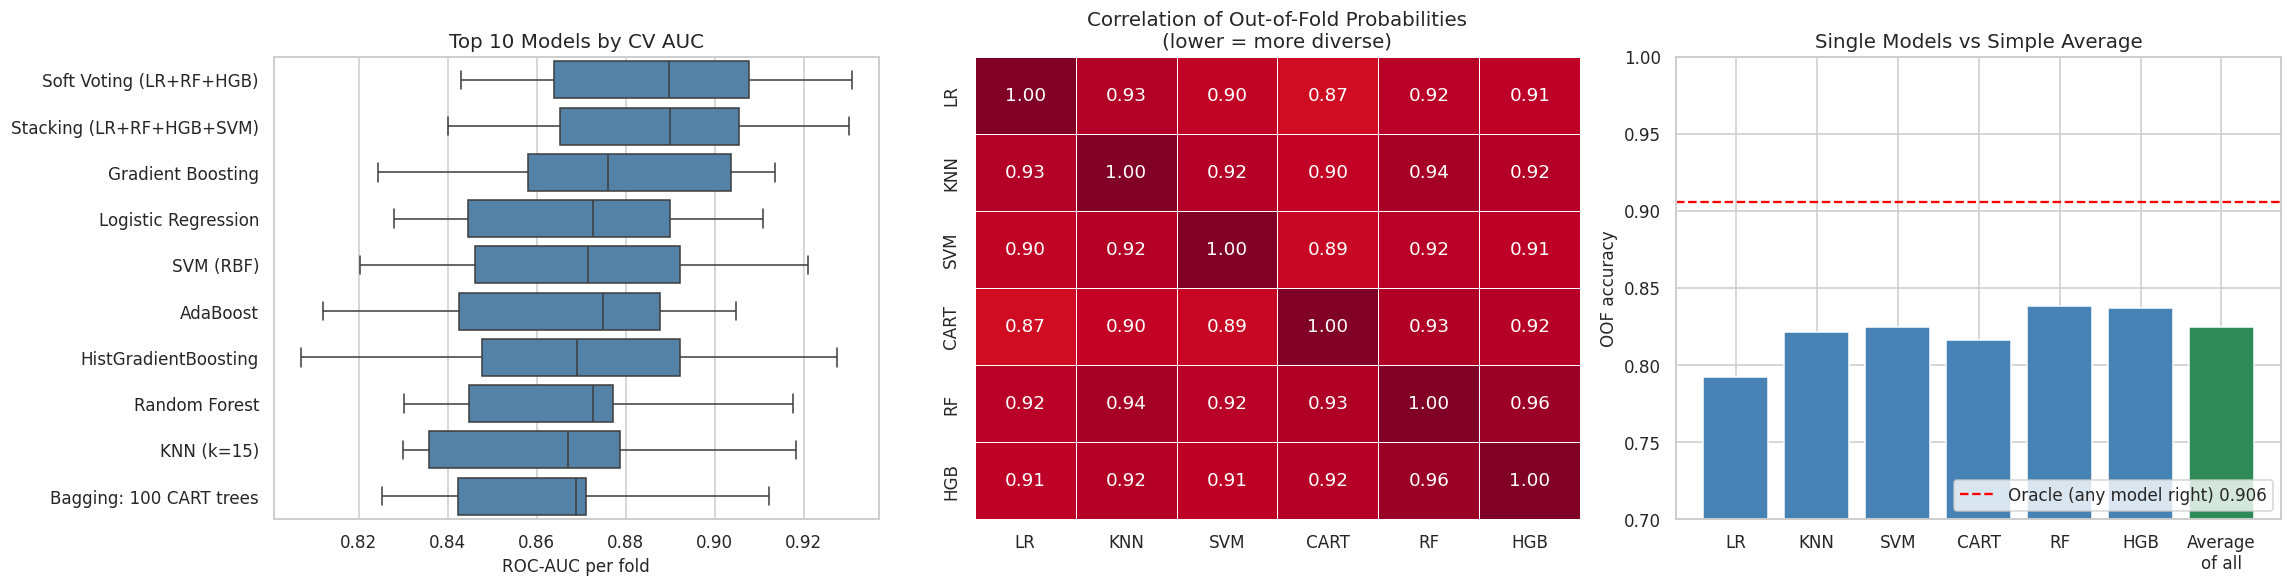

Best single OOF accuracy 0.8385 (RF), average of all six 0.8244, oracle 0.9059.
Averaging ALL six models, weak ones included, did not beat the best single model: ensembles need members that are accurate AND diverse.
If the top models are not significantly different, prefer the simpler, faster, or more interpretable one.


In [ ]:
all_df = pd.DataFrame(results).T.sort_values("cv_auc", ascending=False)
print(all_df.round(4).to_string())

top = list(all_df.dropna(subset=["cv_auc"]).index)
pairs = list(dict.fromkeys([(top[0], top[1]), (top[0], "Logistic Regression"), (top[0], "CART (unpruned)")]))
rows = []
for a, b in pairs:
    d = fold_auc[a] - fold_auc[b]
    try: p = stats.wilcoxon(fold_auc[a], fold_auc[b]).pvalue
    except ValueError: p = np.nan
    rows.append({"comparison": f"{a}  vs  {b}", "mean_AUC_diff": d.mean(), "folds_a_wins": f"{(d > 0).sum()}/10", "wilcoxon_p": p})
print("\nPaired comparisons on the same 10 folds (folds share data, so p-values are somewhat optimistic):")
print(pd.DataFrame(rows).set_index("comparison").round(4).to_string())

# Diversity of out-of-fold predictions
div = {"LR": LogisticRegression(max_iter=2000), "KNN": KNeighborsClassifier(15), "SVM": SVC(probability=True, random_state=RANDOM_STATE),
       "CART": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
       "RF": RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=RANDOM_STATE),
       "HGB": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=150, random_state=RANDOM_STATE)}
oof = pd.DataFrame({n: cross_val_predict(m, X_tr_sel, y_train, cv=cv_fast, method="predict_proba")[:, 1] for n, m in div.items()})
correct = oof.apply(lambda c: (c >= 0.5).astype(int) == y_train.values)

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
sns.boxplot(data=pd.DataFrame(fold_auc)[top[:10]], orient="h", color="steelblue", ax=axes[0])
axes[0].set_xlabel("ROC-AUC per fold"); axes[0].set_title("Top 10 Models by CV AUC")
sns.heatmap(oof.corr(), annot=True, fmt=".2f", cmap="YlOrRd", vmin=0.3, vmax=1, linewidths=0.5, ax=axes[1], cbar=False)
axes[1].set_title("Correlation of Out-of-Fold Probabilities\n(lower = more diverse)")
sa, oracle, ens = correct.mean(), correct.any(axis=1).mean(), accuracy_score(y_train, (oof.mean(axis=1) >= 0.5).astype(int))
axes[2].bar(list(sa.index) + ["Average\nof all"], list(sa.values) + [ens], color=["steelblue"] * 6 + ["seagreen"], edgecolor="white")
axes[2].axhline(oracle, color="red", linestyle="--", label=f"Oracle (any model right) {oracle:.3f}")
axes[2].set_ylim(0.7, 1.0); axes[2].set_ylabel("OOF accuracy"); axes[2].set_title("Single Models vs Simple Average"); axes[2].legend(loc="lower right")
plt.tight_layout(); plt.show()
print(f"Best single OOF accuracy {sa.max():.4f} ({sa.idxmax()}), average of all six {ens:.4f}, oracle {oracle:.4f}.")
if ens <= sa.max():
    print("Averaging ALL six models, weak ones included, did not beat the best single model: ensembles need members that are accurate AND diverse.")
print("If the top models are not significantly different, prefer the simpler, faster, or more interpretable one.")

---
## Step 23: Tune Hyperparameters (and Estimate Honestly with Nested CV)
**Grid search** for the small CART space, **random search** for boosting and forests. The best CV score of a search is optimistic because you picked the winner among many noisy scores; **nested CV** (tune in an inner loop, score in an outer loop) gives an honest estimate.

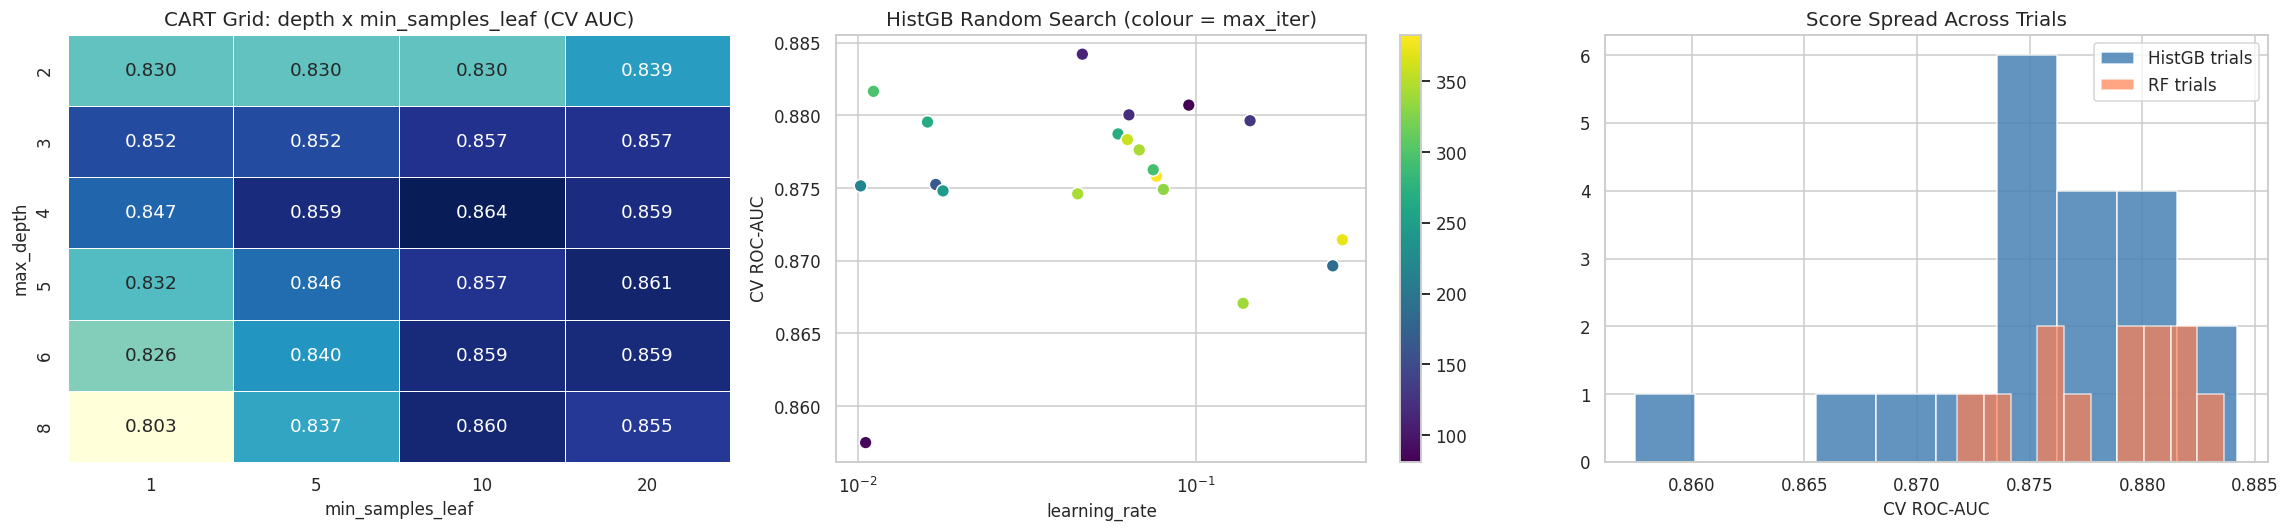

CART   best CV AUC 0.8636  (default depth 4: 0.8496)  {'ccp_alpha': 0.002, 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 10}
HistGB best CV AUC 0.8842  (default: 0.8660)
RF     best CV AUC 0.8836  (default: 0.8659)



Nested CV (CART): non-nested best = 0.8586, nested = 0.8638 ± 0.0174
In theory the non-nested score is optimistic; with a small grid and noisy folds the gap can be tiny or reversed. Report the nested one.


In [ ]:
gs_cart = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                       {"max_depth": [2, 3, 4, 5, 6, 8], "min_samples_leaf": [1, 5, 10, 20],
                        "ccp_alpha": [0, 0.002], "criterion": ["gini", "entropy"]},
                       cv=cv_fast, scoring="roc_auc").fit(X_tr_sel, y_train)

rs_hgb = RandomizedSearchCV(HistGradientBoostingClassifier(random_state=RANDOM_STATE),
                            {"learning_rate": loguniform(0.01, 0.3), "max_iter": randint(80, 400), "max_leaf_nodes": randint(6, 40),
                             "min_samples_leaf": randint(5, 50), "l2_regularization": loguniform(1e-3, 10)},
                            n_iter=20, cv=cv_fast, scoring="roc_auc", random_state=RANDOM_STATE).fit(X_tr_sel, y_train)

rs_rf = RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
                           {"n_estimators": randint(100, 300), "max_depth": [3, 5, 8, 12, None],
                            "min_samples_leaf": randint(1, 15), "max_features": ["sqrt", "log2", 0.5, 0.8]},
                           n_iter=12, cv=cv_fast, scoring="roc_auc", random_state=RANDOM_STATE).fit(X_tr_sel, y_train)

res_cart = pd.DataFrame(gs_cart.cv_results_)
heat = res_cart.groupby(["param_max_depth", "param_min_samples_leaf"])["mean_test_score"].max().unstack().astype(float)
res_h = pd.DataFrame(rs_hgb.cv_results_)

fig, axes = plt.subplots(1, 3, figsize=(21, 5))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="YlGnBu", linewidths=0.5, ax=axes[0], cbar=False)
axes[0].set_title("CART Grid: depth x min_samples_leaf (CV AUC)"); axes[0].set_xlabel("min_samples_leaf"); axes[0].set_ylabel("max_depth")
sc = axes[1].scatter(res_h["param_learning_rate"].astype(float), res_h["mean_test_score"], c=res_h["param_max_iter"].astype(float),
                     cmap="viridis", s=70, edgecolors="white")
axes[1].set_xscale("log"); axes[1].set_xlabel("learning_rate"); axes[1].set_ylabel("CV ROC-AUC"); axes[1].set_title("HistGB Random Search (colour = max_iter)")
plt.colorbar(sc, ax=axes[1])
axes[2].hist(res_h["mean_test_score"], bins=10, color="steelblue", edgecolor="white", alpha=0.85, label="HistGB trials")
axes[2].hist(pd.DataFrame(rs_rf.cv_results_)["mean_test_score"], bins=10, color="coral", edgecolor="white", alpha=0.7, label="RF trials")
axes[2].set_xlabel("CV ROC-AUC"); axes[2].set_title("Score Spread Across Trials"); axes[2].legend()
plt.tight_layout(); plt.show()

print(f"CART   best CV AUC {gs_cart.best_score_:.4f}  (default depth 4: {results['CART (depth 4)']['cv_auc']:.4f})  {gs_cart.best_params_}")
print(f"HistGB best CV AUC {rs_hgb.best_score_:.4f}  (default: {results['HistGradientBoosting']['cv_auc']:.4f})")
print(f"RF     best CV AUC {rs_rf.best_score_:.4f}  (default: {results['Random Forest']['cv_auc']:.4f})")

inner, outer = StratifiedKFold(5, shuffle=True, random_state=1), StratifiedKFold(5, shuffle=True, random_state=2)
small = {"max_depth": [3, 4, 6], "min_samples_leaf": [1, 10, 20], "ccp_alpha": [0, 0.004]}
search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), small, cv=inner, scoring="roc_auc")
nested = cross_val_score(search, X_tr_sel, y_train, cv=outer, scoring="roc_auc")
search.fit(X_tr_sel, y_train)
print(f"\nNested CV (CART): non-nested best = {search.best_score_:.4f}, nested = {nested.mean():.4f} ± {nested.std():.4f}")
print("In theory the non-nested score is optimistic; with a small grid and noisy folds the gap can be tiny or reversed. Report the nested one.")

---
## Step 24: Choose the Final Model (Before Touching the Test Set)
Candidates are compared by **cross-validated ROC-AUC on the training set only**. We write the choice down, fit all candidates on the full training set, and only then open the test set in Step 25.

In [ ]:
candidates = {
    "Logistic Regression":   LogisticRegression(max_iter=2000),
    "CART (tuned)":          clone(gs_cart.best_estimator_),
    "Random Forest (tuned)": clone(rs_rf.best_estimator_),
    "HistGB (tuned)":        clone(rs_hgb.best_estimator_),
    "Soft Voting":           VotingClassifier(base_models(), voting="soft"),
    "Stacking":              StackingClassifier(estimators=base_models() + [("svm", SVC(probability=True, random_state=RANDOM_STATE))],
                                                final_estimator=LogisticRegression(max_iter=2000), cv=5, stack_method="predict_proba"),
}
cv_auc = {n: cross_val_score(clone(m), X_tr_sel, y_train, cv=cv_fast, scoring="roc_auc").mean() for n, m in candidates.items()}
final_name = max(cv_auc, key=cv_auc.get)

print("Cross-validated ROC-AUC on the TRAINING set:")
for n, v in sorted(cv_auc.items(), key=lambda kv: -kv[1]):
    print(f"  {n:24s} {v:.4f}{'   <-- chosen' if n == final_name else ''}")
print(f"\nFinal model chosen BEFORE seeing any test result: {final_name}")

fitted = {n: clone(m).fit(X_tr_sel, y_train) for n, m in candidates.items()}
final_model = fitted[final_name]

Cross-validated ROC-AUC on the TRAINING set:
  Stacking                 0.8892   <-- chosen
  Soft Voting              0.8891
  HistGB (tuned)           0.8842
  Random Forest (tuned)    0.8836
  Logistic Regression      0.8695
  CART (tuned)             0.8636

Final model chosen BEFORE seeing any test result: Stacking


---
## Step 25: Open the Test Set: Full Metric Table
The test set is used **once**. We report many metrics because each answers a different question: overall hit rate (accuracy, balanced accuracy), error types (precision, recall, specificity), agreement beyond chance (MCC, kappa), ranking (ROC-AUC, PR-AUC), and probability quality (log loss, Brier).

                       accuracy  balanced_acc  precision  recall  specificity     f1    mcc  kappa  roc_auc  pr_auc  log_loss  brier
Logistic Regression       0.816         0.785      0.833   0.652        0.918  0.732  0.605  0.594    0.850   0.801     0.451  0.138
CART (tuned)              0.749         0.720      0.707   0.594        0.845  0.646  0.457  0.453    0.806   0.745     0.508  0.165
Random Forest (tuned)     0.788         0.757      0.782   0.623        0.891  0.694  0.542  0.534    0.835   0.820     0.461  0.145
HistGB (tuned)            0.799         0.777      0.770   0.681        0.873  0.723  0.569  0.566    0.844   0.814     0.469  0.145
Soft Voting               0.788         0.762      0.763   0.652        0.873  0.703  0.543  0.539    0.843   0.822     0.452  0.140
Stacking                  0.793         0.770      0.767   0.667        0.873  0.713  0.556  0.553    0.843   0.823     0.442  0.140


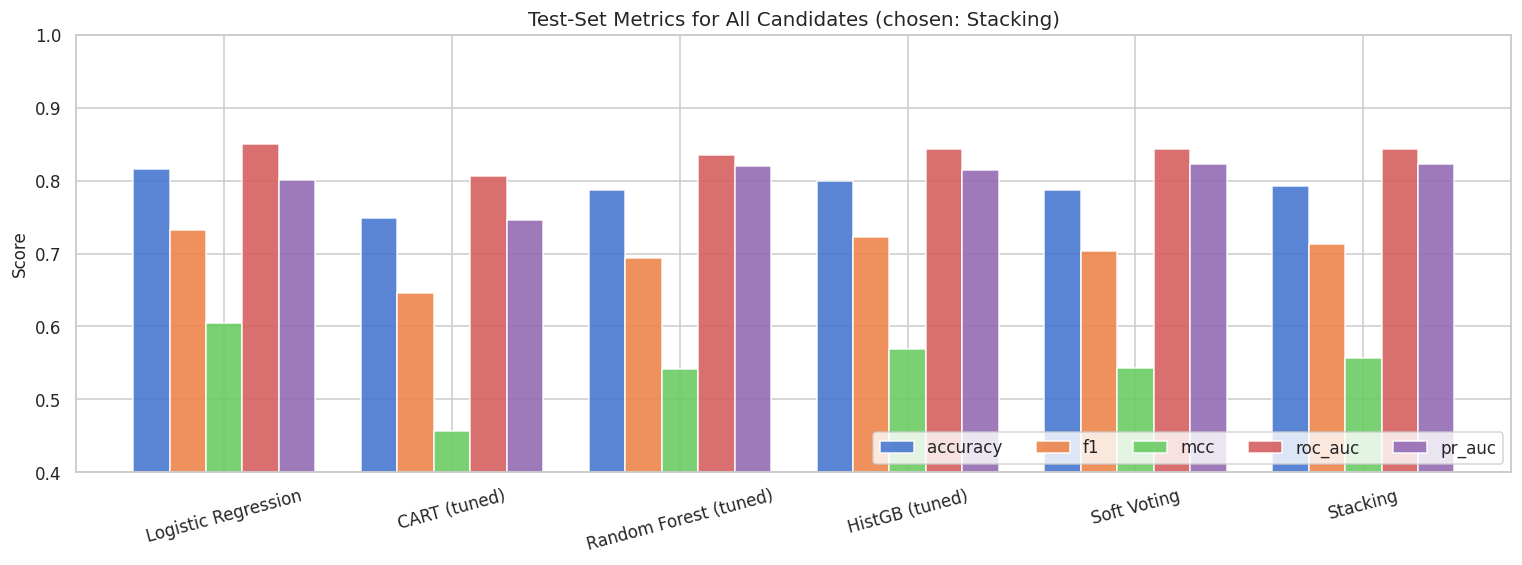


Only 179 test rows: one passenger moves accuracy by 0.56 points. Step 30 puts error bars on this.


In [ ]:
proba = {n: m.predict_proba(X_te_sel)[:, 1] for n, m in fitted.items()}

def full_metrics(y_true, p, thr=0.5):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_true, pred), "balanced_acc": balanced_accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
            "specificity": tn / (tn + fp), "f1": f1_score(y_true, pred), "mcc": matthews_corrcoef(y_true, pred),
            "kappa": cohen_kappa_score(y_true, pred), "roc_auc": roc_auc_score(y_true, p),
            "pr_auc": average_precision_score(y_true, p), "log_loss": log_loss(y_true, p), "brier": brier_score_loss(y_true, p)}

test_df = pd.DataFrame({n: full_metrics(y_test, p) for n, p in proba.items()}).T
print(test_df.round(3).to_string())

fig, ax = plt.subplots(figsize=(14, 5.3))
test_df[["accuracy", "f1", "mcc", "roc_auc", "pr_auc"]].plot(kind="bar", ax=ax, edgecolor="white", alpha=0.9, width=0.8)
ax.set_ylim(0.4, 1.0); ax.set_ylabel("Score"); ax.set_title(f"Test-Set Metrics for All Candidates (chosen: {final_name})")
ax.tick_params(axis="x", rotation=15); ax.legend(ncol=5, loc="lower right")
plt.tight_layout(); plt.show()
print(f"\nOnly {len(y_test)} test rows: one passenger moves accuracy by {100 / len(y_test):.2f} points. Step 30 puts error bars on this.")

---
## Step 26: Confusion Matrix and Classification Report
The confusion matrix shows **which kind of mistake** the model makes. Row-normalising it gives recall per class.

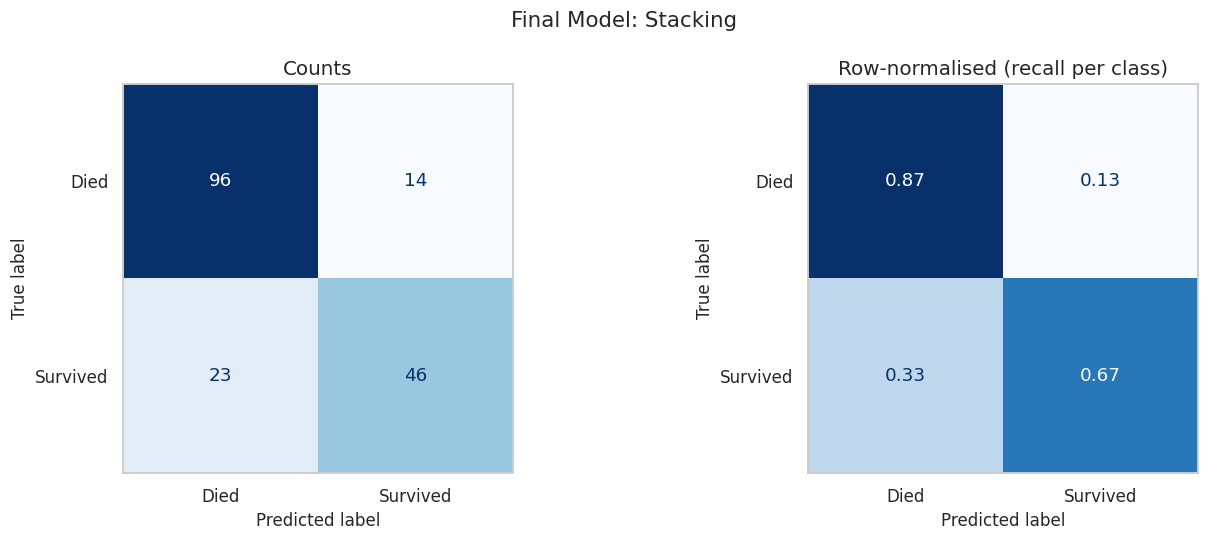

              precision    recall  f1-score   support

        Died      0.807     0.873     0.838       110
    Survived      0.767     0.667     0.713        69

    accuracy                          0.793       179
   macro avg      0.787     0.770     0.776       179
weighted avg      0.791     0.793     0.790       179



In [ ]:
pred_final = (proba[final_name] >= 0.5).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(f"Final Model: {final_name}", fontsize=14)
ConfusionMatrixDisplay.from_predictions(y_test, pred_final, display_labels=["Died", "Survived"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Counts"); axes[0].grid(False)
ConfusionMatrixDisplay.from_predictions(y_test, pred_final, display_labels=["Died", "Survived"], normalize="true",
                                        cmap="Blues", colorbar=False, ax=axes[1], values_format=".2f")
axes[1].set_title("Row-normalised (recall per class)"); axes[1].grid(False)
plt.tight_layout(); plt.show()
print(classification_report(y_test, pred_final, target_names=["Died", "Survived"], digits=3))

---
## Step 27: ROC and Precision-Recall Curves
Threshold-free views of ranking quality for every candidate. The **ROC** curve plots recall against the false-positive rate; the **PR** curve plots precision against recall and is more informative when the positive class matters most.

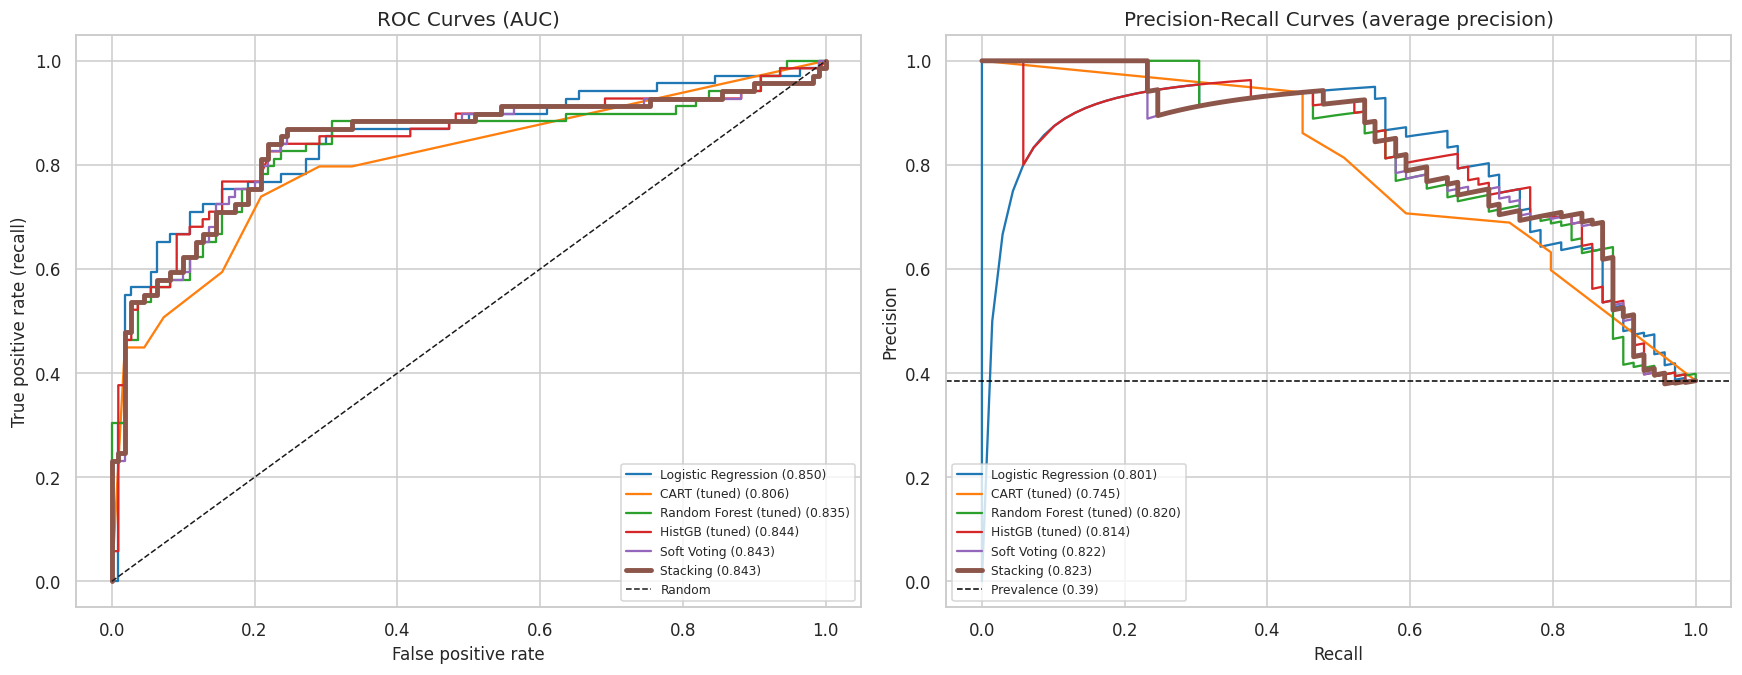

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.3))
pal = sns.color_palette("tab10", len(proba))
for (n, p), color in zip(proba.items(), pal):
    lw = 3.2 if n == final_name else 1.5
    fpr, tpr, _ = roc_curve(y_test, p); axes[0].plot(fpr, tpr, color=color, linewidth=lw, label=f"{n} ({roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); axes[1].plot(rc, pr, color=color, linewidth=lw, label=f"{n} ({average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Random")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)"); axes[0].set_title("ROC Curves (AUC)"); axes[0].legend(loc="lower right", fontsize=8)
axes[1].axhline(y_test.mean(), color="black", linestyle="--", linewidth=1, label=f"Prevalence ({y_test.mean():.2f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall Curves (average precision)"); axes[1].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

---
## Step 28: Calibration: Can We Trust the Probabilities?
A calibrated model that says 70% is right about 70% of the time. Good ranking (AUC) does not guarantee this. We draw a **reliability diagram** and try **isotonic** and **sigmoid (Platt)** recalibration.

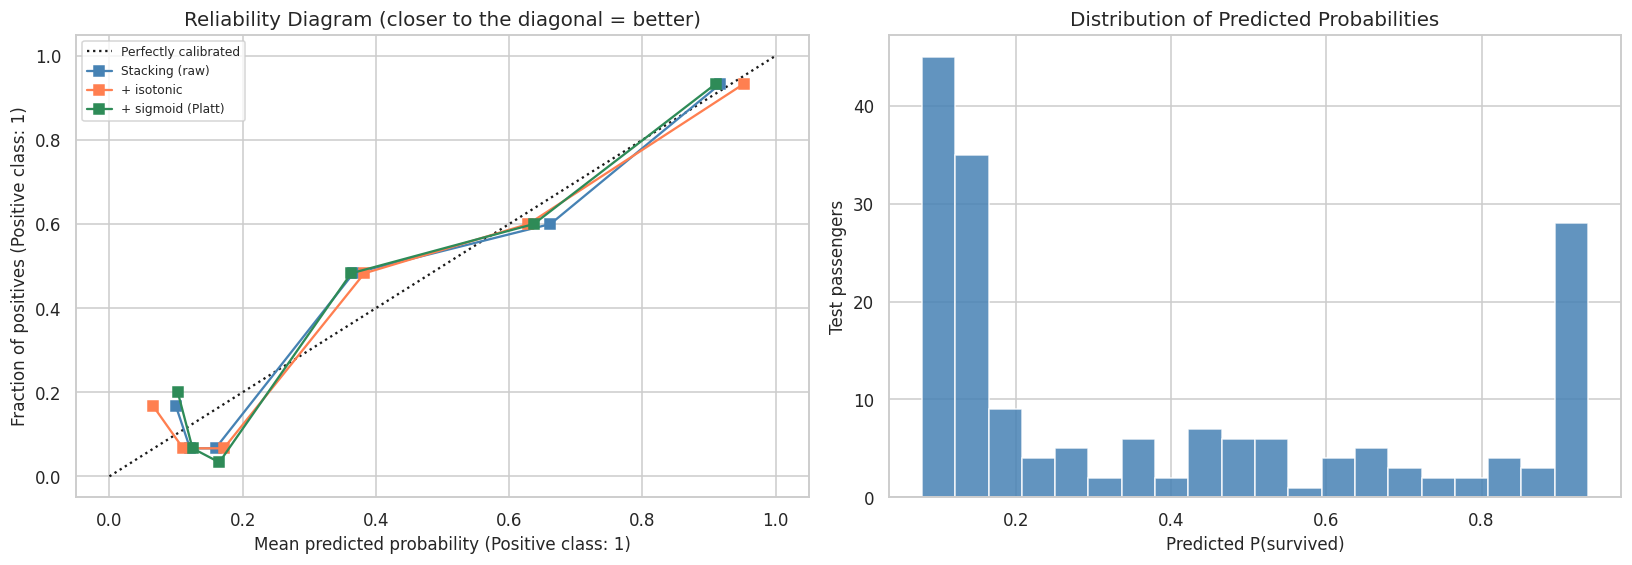

Stacking (raw)               Brier = 0.1398   log loss = 0.4421   AUC = 0.8428
+ isotonic                   Brier = 0.1380   log loss = 0.6471   AUC = 0.8453
+ sigmoid (Platt)            Brier = 0.1368   log loss = 0.4367   AUC = 0.8416

The raw model was already close to calibrated: recalibration gives no real gain (isotonic can even hurt on small data).


In [ ]:
cal_iso = CalibratedClassifierCV(clone(final_model), method="isotonic", cv=5).fit(X_tr_sel, y_train)
cal_sig = CalibratedClassifierCV(clone(final_model), method="sigmoid",  cv=5).fit(X_tr_sel, y_train)
cal_probs = {f"{final_name} (raw)": proba[final_name], "+ isotonic": cal_iso.predict_proba(X_te_sel)[:, 1],
             "+ sigmoid (Platt)": cal_sig.predict_proba(X_te_sel)[:, 1]}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.3))
for (n, p), c in zip(cal_probs.items(), ["steelblue", "coral", "seagreen"]):
    CalibrationDisplay.from_predictions(y_test, p, n_bins=6, strategy="quantile", name=n, ax=axes[0], color=c)
axes[0].set_title("Reliability Diagram (closer to the diagonal = better)"); axes[0].legend(loc="upper left", fontsize=8)
axes[1].hist(proba[final_name], bins=20, color="steelblue", edgecolor="white", alpha=0.85)
axes[1].set_xlabel("Predicted P(survived)"); axes[1].set_ylabel("Test passengers"); axes[1].set_title("Distribution of Predicted Probabilities")
plt.tight_layout(); plt.show()

bs = {n: brier_score_loss(y_test, p) for n, p in cal_probs.items()}
for n, p in cal_probs.items():
    print(f"{n:28s} Brier = {bs[n]:.4f}   log loss = {log_loss(y_test, p):.4f}   AUC = {roc_auc_score(y_test, p):.4f}")
if min(bs.values()) >= bs[f"{final_name} (raw)"] - 0.003:
    print("\nThe raw model was already close to calibrated: recalibration gives no real gain (isotonic can even hurt on small data).")
else:
    print("\nRecalibration lowered the Brier score: use the calibrated probabilities if you act on the numbers.")

---
## Step 29: Choose the Decision Threshold (on Training Data, with a Cost)
0.5 is a convention. Pick the threshold on **out-of-fold training predictions** using an explicit cost, then check it on the test set. Here a missed survivor (false negative) is assumed to cost **twice** a false alarm.

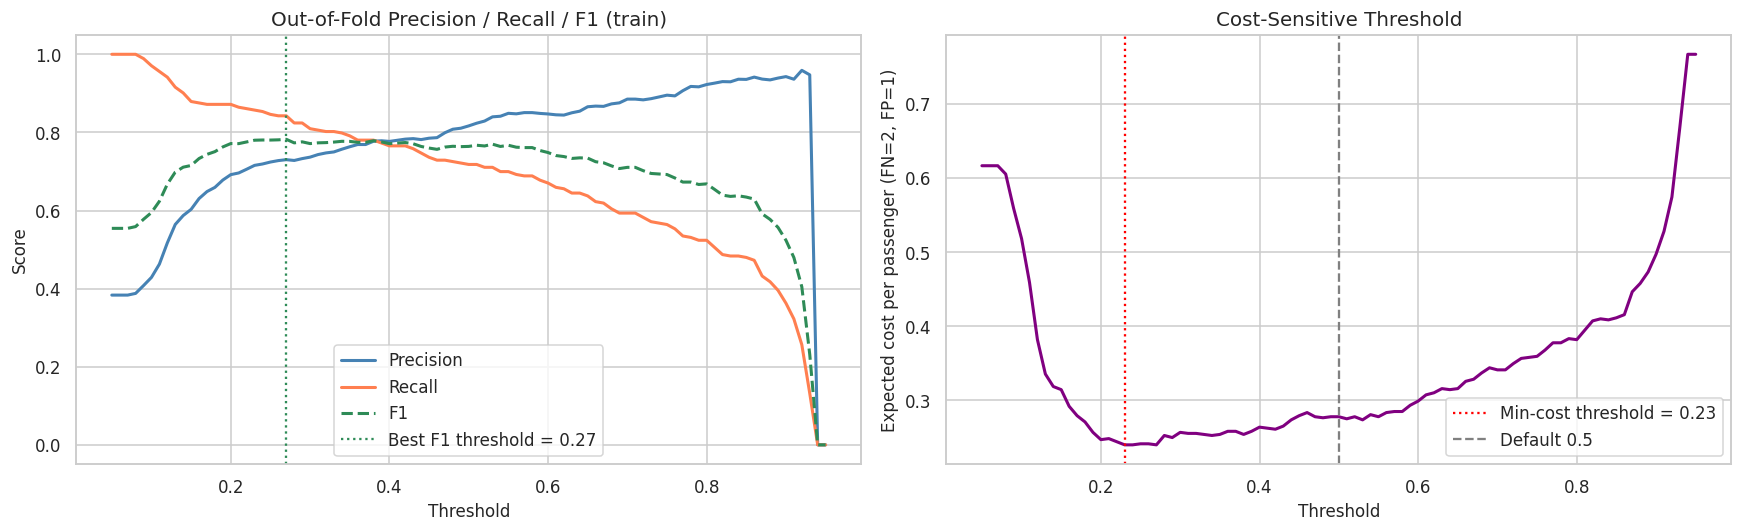

Test @ default 0.5        recall = 0.667  precision = 0.767  F1 = 0.713  FN = 23  FP = 14  cost/passenger = 0.335
Test @ best F1 (0.27)     recall = 0.841  precision = 0.690  F1 = 0.758  FN = 11  FP = 26  cost/passenger = 0.268
Test @ min cost (0.23)    recall = 0.870  precision = 0.690  F1 = 0.769  FN = 9  FP = 27  cost/passenger = 0.251

The threshold was chosen on TRAIN predictions only, so the test numbers are an honest check of that choice.


In [ ]:
oof_final = cross_val_predict(clone(final_model), X_tr_sel, y_train, cv=cv_fast, method="predict_proba")[:, 1]
COST_FN, COST_FP = 2.0, 1.0
grid_thr = np.linspace(0.05, 0.95, 91)
f1c, costc, prc, rcc = [], [], [], []
for t in grid_thr:
    pr_ = (oof_final >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pr_, labels=[0, 1]).ravel()
    f1c.append(f1_score(y_train, pr_, zero_division=0)); prc.append(precision_score(y_train, pr_, zero_division=0))
    rcc.append(recall_score(y_train, pr_)); costc.append((COST_FN * fn + COST_FP * fp) / len(y_train))
thr_f1, thr_cost = grid_thr[int(np.argmax(f1c))], grid_thr[int(np.argmin(costc))]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(grid_thr, prc, color="steelblue", linewidth=2, label="Precision"); axes[0].plot(grid_thr, rcc, color="coral", linewidth=2, label="Recall")
axes[0].plot(grid_thr, f1c, color="seagreen", linewidth=2, linestyle="--", label="F1")
axes[0].axvline(thr_f1, color="seagreen", linestyle=":", label=f"Best F1 threshold = {thr_f1:.2f}")
axes[0].set_xlabel("Threshold"); axes[0].set_ylabel("Score"); axes[0].set_title("Out-of-Fold Precision / Recall / F1 (train)"); axes[0].legend()
axes[1].plot(grid_thr, costc, color="purple", linewidth=2)
axes[1].axvline(thr_cost, color="red", linestyle=":", label=f"Min-cost threshold = {thr_cost:.2f}"); axes[1].axvline(0.5, color="grey", linestyle="--", label="Default 0.5")
axes[1].set_xlabel("Threshold"); axes[1].set_ylabel(f"Expected cost per passenger (FN={COST_FN:g}, FP={COST_FP:g})")
axes[1].set_title("Cost-Sensitive Threshold"); axes[1].legend()
plt.tight_layout(); plt.show()

for label, t in [("default 0.5", 0.5), (f"best F1 ({thr_f1:.2f})", thr_f1), (f"min cost ({thr_cost:.2f})", thr_cost)]:
    m = full_metrics(y_test, proba[final_name], t)
    tn, fp, fn, tp = confusion_matrix(y_test, (proba[final_name] >= t).astype(int), labels=[0, 1]).ravel()
    print(f"Test @ {label:18s} recall = {m['recall']:.3f}  precision = {m['precision']:.3f}  F1 = {m['f1']:.3f}  FN = {fn}  FP = {fp}  cost/passenger = {(COST_FN * fn + COST_FP * fp) / len(y_test):.3f}")
print("\nThe threshold was chosen on TRAIN predictions only, so the test numbers are an honest check of that choice.")

---
## Step 30: Quantify Uncertainty: Bootstrap CIs and McNemar's Test
A test metric from 179 rows is **noisy**. A **bootstrap** resamples the test predictions to give a confidence interval. **McNemar's exact test** asks whether two models make *different* errors more often than chance explains.

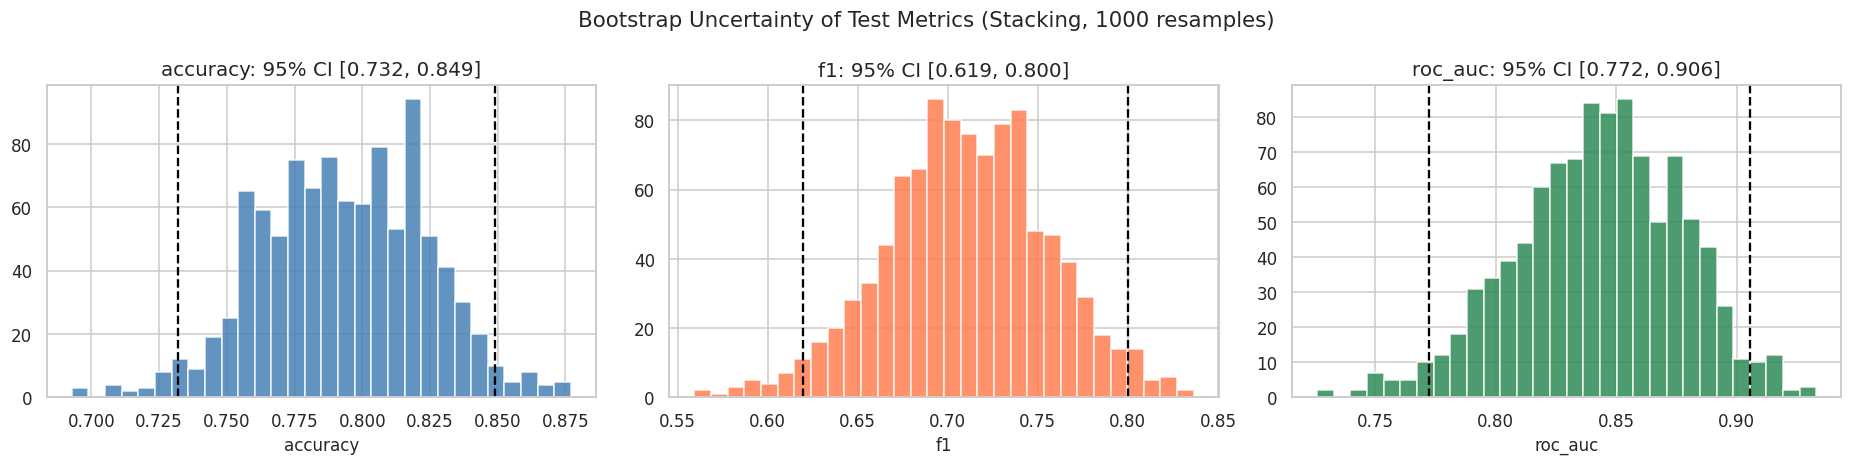

McNemar: Stacking vs Logistic Regression: only Logistic Regression right = 13, only Stacking right = 9, exact p = 0.523
A wide interval or a large McNemar p-value means this test set cannot separate the top models.


In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
yt, n_t = y_test.values, len(y_test)
boot = {"accuracy": [], "f1": [], "roc_auc": []}
for _ in range(1000):
    ix = rng.integers(0, n_t, n_t)
    if len(np.unique(yt[ix])) < 2: continue
    pr_ = (proba[final_name][ix] >= 0.5).astype(int)
    boot["accuracy"].append(accuracy_score(yt[ix], pr_)); boot["f1"].append(f1_score(yt[ix], pr_))
    boot["roc_auc"].append(roc_auc_score(yt[ix], proba[final_name][ix]))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
fig.suptitle(f"Bootstrap Uncertainty of Test Metrics ({final_name}, 1000 resamples)", fontsize=14)
for ax, (m, v), c in zip(axes, boot.items(), ["steelblue", "coral", "seagreen"]):
    lo_, hi_ = np.percentile(v, [2.5, 97.5])
    ax.hist(v, bins=30, color=c, edgecolor="white", alpha=0.85); ax.axvline(lo_, color="black", linestyle="--"); ax.axvline(hi_, color="black", linestyle="--")
    ax.set_title(f"{m}: 95% CI [{lo_:.3f}, {hi_:.3f}]"); ax.set_xlabel(m)
plt.tight_layout(); plt.show()

ref = "Logistic Regression" if final_name != "Logistic Regression" else "CART (tuned)"
ok_f, ok_r = (proba[final_name] >= 0.5).astype(int) == yt, (proba[ref] >= 0.5).astype(int) == yt
b, c = int((ok_r & ~ok_f).sum()), int((~ok_r & ok_f).sum())
p_mc = stats.binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0
print(f"McNemar: {final_name} vs {ref}: only {ref} right = {b}, only {final_name} right = {c}, exact p = {p_mc:.3f}")
print("A wide interval or a large McNemar p-value means this test set cannot separate the top models.")

---
## Step 31: Diagnose Bias vs Variance: Learning Curve
Train and validation scores against **training-set size** tell you whether more data would help (large gap = variance) or whether you need better features or models (both curves low and flat = bias).

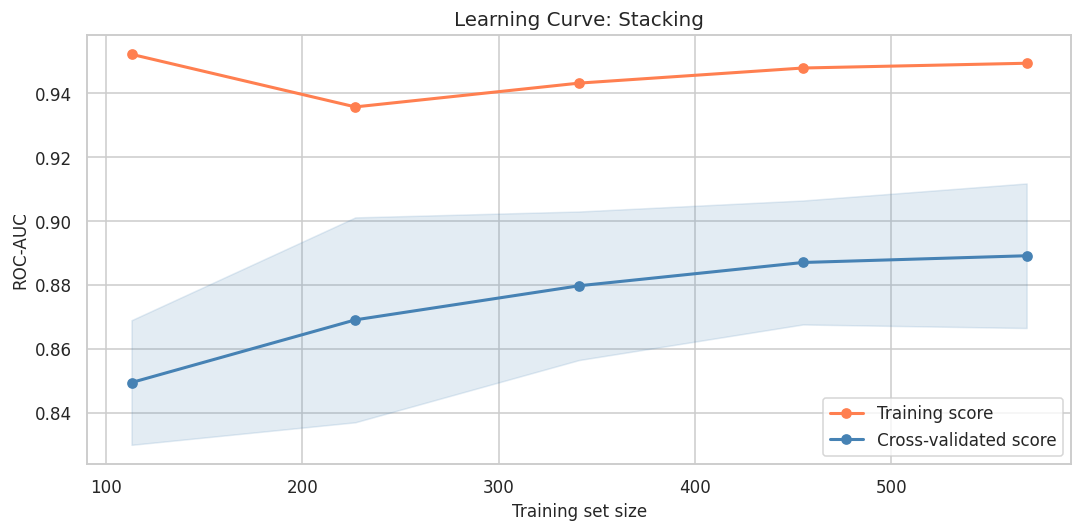

Final train-validation gap: 0.060   Gain from the last 20% of data: +0.0021


In [ ]:
sizes, tr_lc, va_lc = learning_curve(clone(final_model), X_tr_sel, y_train, cv=cv_fast, scoring="roc_auc",
                                     train_sizes=np.linspace(0.2, 1.0, 5), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sizes, tr_lc.mean(axis=1), "o-", color="coral", linewidth=2, label="Training score")
ax.plot(sizes, va_lc.mean(axis=1), "o-", color="steelblue", linewidth=2, label="Cross-validated score")
ax.fill_between(sizes, va_lc.mean(axis=1) - va_lc.std(axis=1), va_lc.mean(axis=1) + va_lc.std(axis=1), color="steelblue", alpha=0.15)
ax.set_xlabel("Training set size"); ax.set_ylabel("ROC-AUC"); ax.set_title(f"Learning Curve: {final_name}"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
print(f"Final train-validation gap: {tr_lc.mean(axis=1)[-1] - va_lc.mean(axis=1)[-1]:.3f}   Gain from the last 20% of data: {va_lc.mean(axis=1)[-1] - va_lc.mean(axis=1)[-2]:+.4f}")

---
## Step 32: Interpret the Model: Permutation Importance and Partial Dependence
**Permutation importance** shuffles one feature on the **test set** and measures the drop in score (model-agnostic, honest). **Partial dependence** shows how the average prediction changes as one feature varies. Correlated features share credit, so a low importance can mean redundant, not useless.

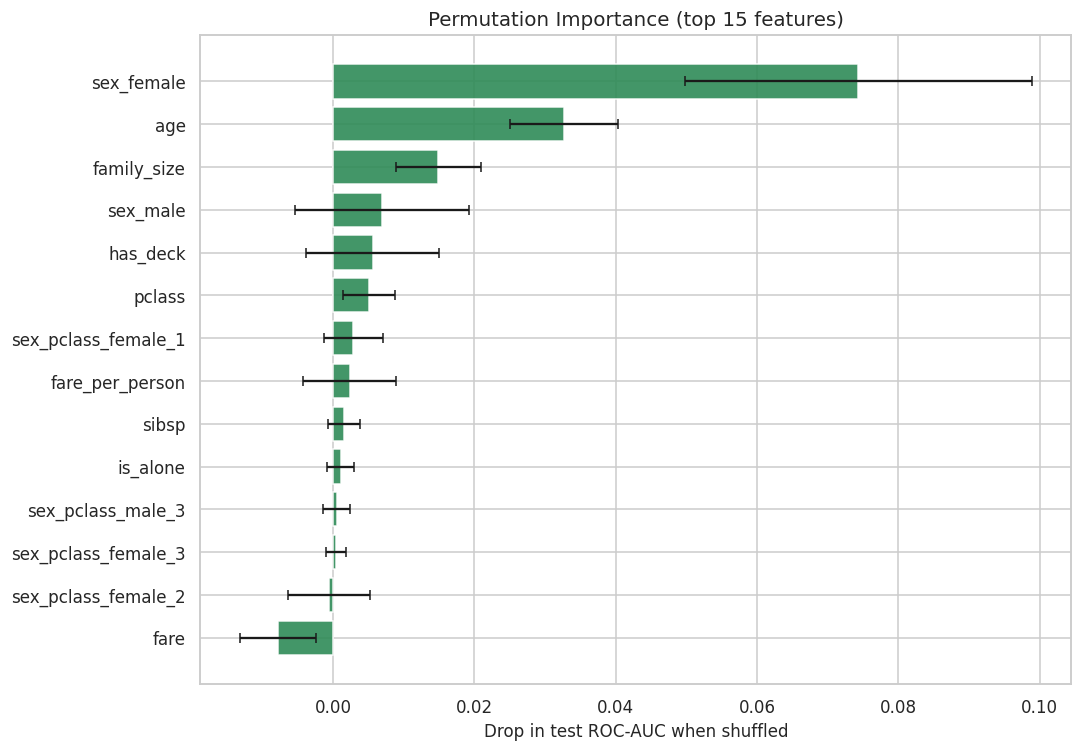

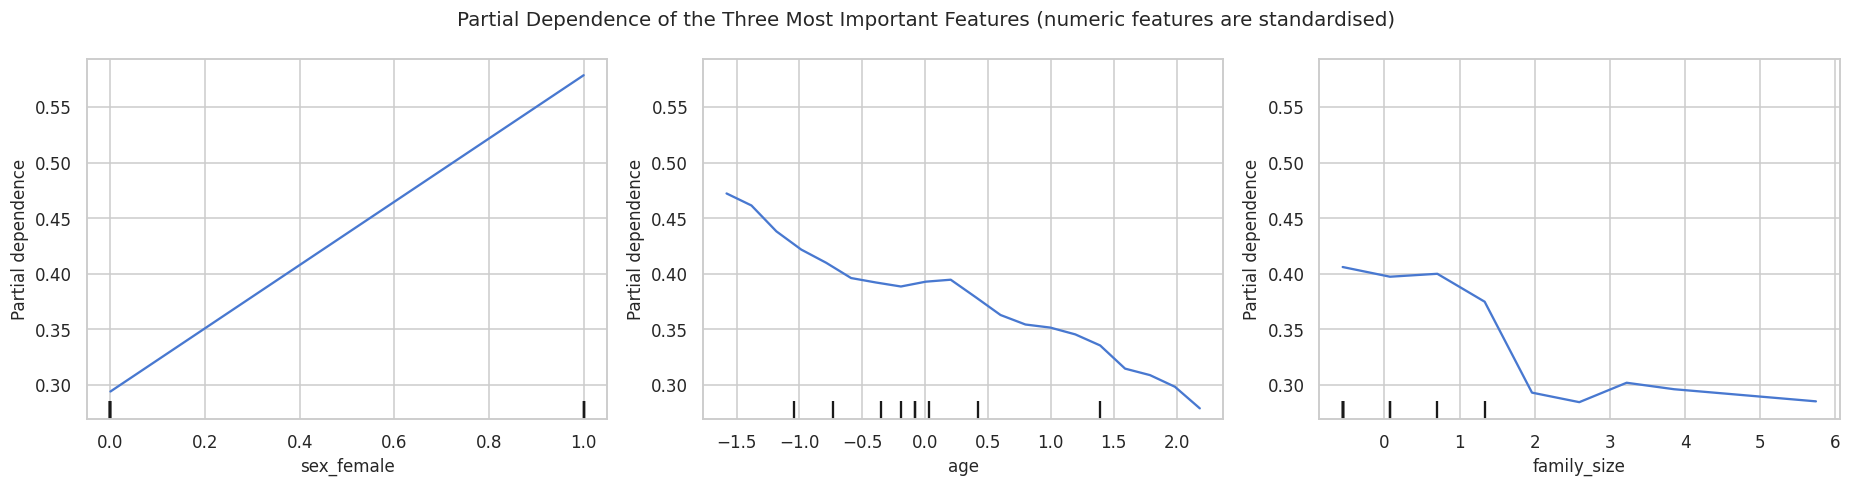

Most important: ['sex_female', 'age', 'family_size']


In [ ]:
perm = permutation_importance(final_model, X_te_sel, y_test, scoring="roc_auc", n_repeats=15, random_state=RANDOM_STATE)
perm_df = pd.DataFrame({"feature": X_te_sel.columns, "importance": perm.importances_mean, "std": perm.importances_std}).sort_values("importance")

fig, ax = plt.subplots(figsize=(10, 7))
top15 = perm_df.tail(15)
ax.barh(top15["feature"], top15["importance"], xerr=top15["std"], color="seagreen", edgecolor="white", alpha=0.9, capsize=3)
ax.set_xlabel("Drop in test ROC-AUC when shuffled"); ax.set_title("Permutation Importance (top 15 features)")
plt.tight_layout(); plt.show()

top3 = perm_df["feature"].tail(3).tolist()[::-1]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
PartialDependenceDisplay.from_estimator(final_model, X_te_sel, top3, grid_resolution=20, kind="average", ax=axes)
fig.suptitle("Partial Dependence of the Three Most Important Features (numeric features are standardised)", fontsize=13)
plt.tight_layout(); plt.show()
print("Most important:", top3)

---
## Step 33: Error Analysis and Subgroup Performance
A good overall score can hide a weak subgroup. We map predictions back to the **raw** test rows, compare accuracy and recall by group, and list the **most confidently wrong** predictions to investigate by hand.

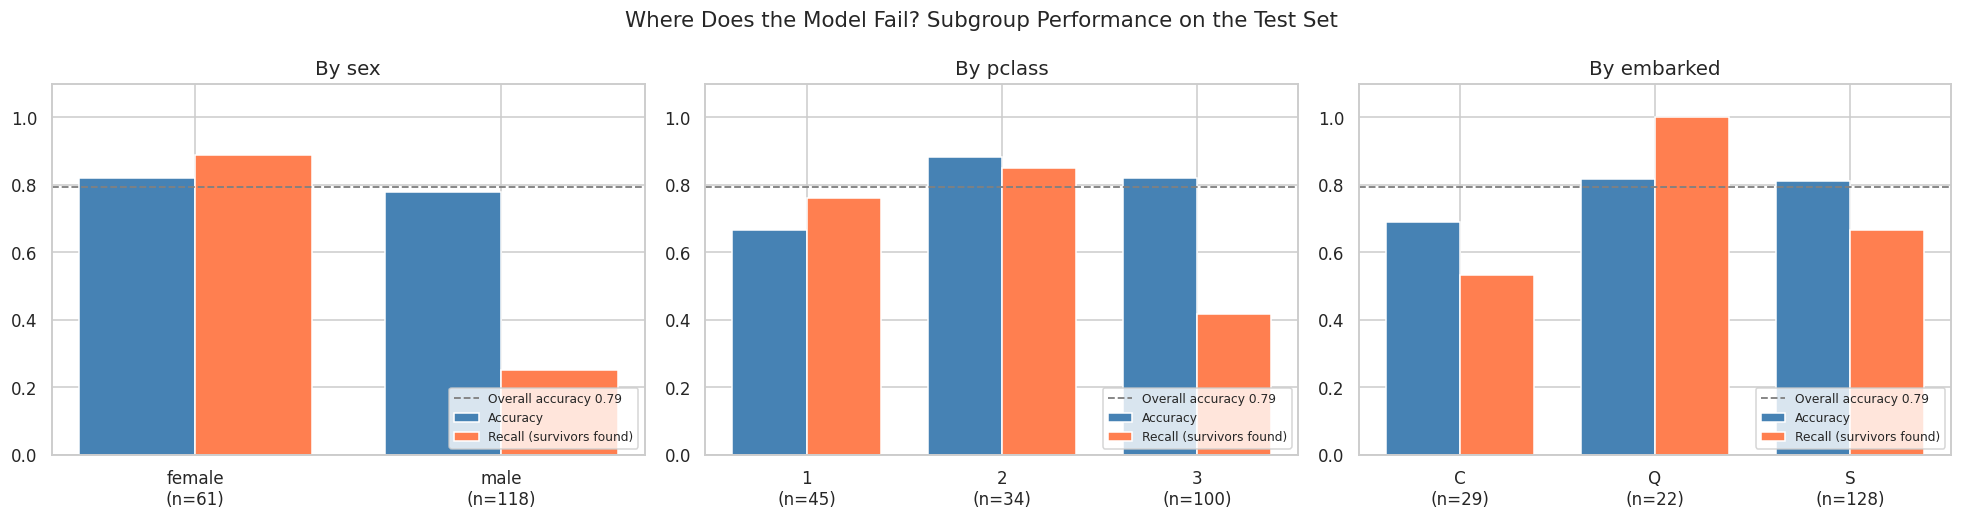

Most confidently wrong predictions:
     pclass     sex   age    fare embarked deck  actual  p_survive
271       3    male  25.0    0.00        S  NaN       1       0.08
570       2    male  62.0   10.50        S  NaN       1       0.08
297       1  female   2.0  151.55        S    C       0       0.92
199       2  female  24.0   13.00        S  NaN       0       0.92
804       3    male  27.0    6.98        S  NaN       1       0.09
444       3    male   NaN    8.11        S  NaN       1       0.10
455       3    male  29.0    7.90        C  NaN       1       0.10
17        2    male   NaN   13.00        S  NaN       1       0.11


In [ ]:
res_df = X_test.loc[X_te_sel.index].copy()
res_df["actual"], res_df["p_survive"], res_df["pred"] = y_test.loc[X_te_sel.index].values, proba[final_name], pred_final
res_df["correct"] = res_df["pred"] == res_df["actual"]
overall = res_df["correct"].mean()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
fig.suptitle("Where Does the Model Fail? Subgroup Performance on the Test Set", fontsize=14)
for ax, col in zip(axes, ["sex", "pclass", "embarked"]):
    g = res_df.groupby(col).apply(lambda d: pd.Series({"accuracy": d["correct"].mean(), "n": len(d),
                                                       "recall": recall_score(d["actual"], d["pred"], zero_division=0)}))
    xx, w = np.arange(len(g)), 0.38
    ax.bar(xx - w / 2, g["accuracy"], w, color="steelblue", edgecolor="white", label="Accuracy")
    ax.bar(xx + w / 2, g["recall"],   w, color="coral", edgecolor="white", label="Recall (survivors found)")
    ax.set_xticks(xx); ax.set_xticklabels([f"{i}\n(n={int(n)})" for i, n in zip(g.index, g["n"])])
    ax.axhline(overall, color="grey", linestyle="--", linewidth=1.2, label=f"Overall accuracy {overall:.2f}")
    ax.set_ylim(0, 1.1); ax.set_title(f"By {col}"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

wrong = res_df[~res_df["correct"]].assign(conf=lambda d: (d["p_survive"] - d["actual"]).abs()).sort_values("conf", ascending=False)
print("Most confidently wrong predictions:")
print(wrong[["pclass", "sex", "age", "fare", "embarked", "deck", "actual", "p_survive"]].head(8).round(2).to_string())

---
## Step 34: Results Summary and Model Card
One table with every candidate's cross-validated and test performance, plus a short **model card** stating what the model is for, how good it is (with uncertainty), and where it should not be used.

In [ ]:
summary = pd.DataFrame({"CV ROC-AUC (train)": pd.Series(cv_auc), "Test ROC-AUC": test_df["roc_auc"], "Test accuracy": test_df["accuracy"],
                        "Test F1": test_df["f1"], "Test MCC": test_df["mcc"], "Test Brier": test_df["brier"]}
                       ).sort_values("CV ROC-AUC (train)", ascending=False)
print(summary.round(4).to_string())

lo_a, hi_a = np.percentile(boot["accuracy"], [2.5, 97.5]); lo_u, hi_u = np.percentile(boot["roc_auc"], [2.5, 97.5])
print(f"""
MODEL CARD
  Task:            predict Titanic survival from boarding information
  Final model:     {final_name}  (chosen by training-set CV before the test set was opened)
  Features:        {X_tr_sel.shape[1]} engineered, imputed, encoded, scaled features
  Training data:   {len(X_train)} passengers      Test data: {len(X_test)} passengers
  Test accuracy:   {test_df.loc[final_name, 'accuracy']:.3f}  (95% CI {lo_a:.3f} to {hi_a:.3f})
  Test ROC-AUC:    {test_df.loc[final_name, 'roc_auc']:.3f}  (95% CI {lo_u:.3f} to {hi_u:.3f})
  Calibration:     Brier {test_df.loc[final_name, 'brier']:.3f}; see the reliability diagram in Step 28
  Known weakness:  see the subgroup table and confidently-wrong cases in Step 33
  Not suitable for: decisions about real people (small, historical, non-representative sample)""")

                       CV ROC-AUC (train)  Test ROC-AUC  Test accuracy  Test F1  Test MCC  Test Brier
Stacking                           0.8892        0.8428         0.7933   0.7132    0.5561      0.1398
Soft Voting                        0.8891        0.8427         0.7877   0.7031    0.5435      0.1404
HistGB (tuned)                     0.8842        0.8437         0.7989   0.7231    0.5688      0.1451
Random Forest (tuned)              0.8836        0.8349         0.7877   0.6935    0.5423      0.1453
Logistic Regression                0.8695        0.8502         0.8156   0.7317    0.6048      0.1379
CART (tuned)                       0.8636        0.8062         0.7486   0.6457    0.4572      0.1652

MODEL CARD
  Task:            predict Titanic survival from boarding information
  Final model:     Stacking  (chosen by training-set CV before the test set was opened)
  Features:        14 engineered, imputed, encoded, scaled features
  Training data:   712 passengers      Test data

---
## Step 35: Build the Leak-Proof Production Pipeline, Save It, Score New Data
Steps 8-14 prepared the data by hand to show each stage. In production we want **one object** that takes a **raw row** and returns a prediction, and that refits every step inside each CV fold. We rebuild the same workflow as a `Pipeline`, check that it agrees with the manual version, save it with `joblib`, and score new passengers (including one with a missing age).

In [ ]:
num_c, skew_c = ["age", "sibsp", "parch", "family_size", "pclass"], ["fare", "fare_per_person"]
cat_c, bin_c = ["sex", "embarked", "sex_pclass"], ["is_alone", "has_deck", "age_missing", "is_child"]

prep = ColumnTransformer([
    ("num",  Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_c),
    ("skew", Pipeline([("imp", SimpleImputer(strategy="median")), ("log", FunctionTransformer(np.log1p)), ("sc", StandardScaler())]), skew_c),
    ("cat",  Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_c),
    ("bin",  "passthrough", bin_c)])

selector_step = SelectKBest(partial(mutual_info_classif, random_state=RANDOM_STATE), k=sel_k) if sel_k < n_feat else "passthrough"
prod = Pipeline([("fe", FunctionTransformer(engineer)), ("prep", prep), ("sel", selector_step), ("clf", clone(final_model))])

# 1) Cross-validation WITH every preparation step refitted inside each fold (no leakage at all)
cv_prod  = cross_val_score(clone(prod), X_train, y_train, cv=cv_fast, scoring="roc_auc").mean()
cv_manual = cross_val_score(clone(final_model), X_tr_sel, y_train, cv=cv_fast, scoring="roc_auc").mean()
print(f"CV ROC-AUC, manual matrices (small leak): {cv_manual:.4f}")
print(f"CV ROC-AUC, leak-proof Pipeline:          {cv_prod:.4f}   (difference {cv_manual - cv_prod:+.4f})")

# 2) Fit on the raw training rows, score the raw test rows
prod.fit(X_train, y_train)
p_prod = prod.predict_proba(X_test)[:, 1]
print(f"Test ROC-AUC, pipeline: {roc_auc_score(y_test, p_prod):.4f}   manual: {roc_auc_score(y_test, proba[final_name]):.4f}")

# 3) Save, reload, score brand-new passengers
joblib.dump(prod, "titanic_survival_pipeline.joblib")
loaded = joblib.load("titanic_survival_pipeline.joblib")
new = pd.DataFrame([
    {"pclass": 1, "sex": "female", "age": 29.0,   "sibsp": 0, "parch": 1, "fare": 120.0, "embarked": "C", "deck": "B"},
    {"pclass": 3, "sex": "male",   "age": 22.0,   "sibsp": 0, "parch": 0, "fare": 7.9,   "embarked": "S", "deck": np.nan},
    {"pclass": 3, "sex": "female", "age": np.nan, "sibsp": 1, "parch": 2, "fare": 15.5,  "embarked": "Q", "deck": np.nan},
])[X.columns]
out = new.copy()
out["p_survive"] = loaded.predict_proba(new)[:, 1].round(3)
out["prediction"] = np.where(loaded.predict(new) == 1, "Survived", "Died")
print("\n" + out.to_string())
assert np.allclose(loaded.predict_proba(X_test)[:, 1], p_prod)
print("\nReloaded pipeline reproduces the predictions exactly, and handles raw strings and a missing age with no extra code.")
print("To load it elsewhere, the function 'engineer' must be importable (put it in a .py module). Pin the scikit-learn version.")

CV ROC-AUC, manual matrices (small leak): 0.8892
CV ROC-AUC, leak-proof Pipeline:          0.8837   (difference +0.0055)


Test ROC-AUC, pipeline: 0.8430   manual: 0.8428

   pclass     sex   age  sibsp  parch   fare embarked deck  p_survive prediction
0       1  female  29.0      0      1  120.0        C    B      0.937   Survived
1       3    male  22.0      0      0    7.9        S  NaN      0.094       Died
2       3  female   NaN      1      2   15.5        Q  NaN      0.508   Survived

Reloaded pipeline reproduces the predictions exactly, and handles raw strings and a missing age with no extra code.
To load it elsewhere, the function 'engineer' must be importable (put it in a .py module). Pin the scikit-learn version.


---
## Step 36: The End-to-End Dashboard
Four panels that tell the story: **comparison**, **discrimination**, **errors**, **drivers**.

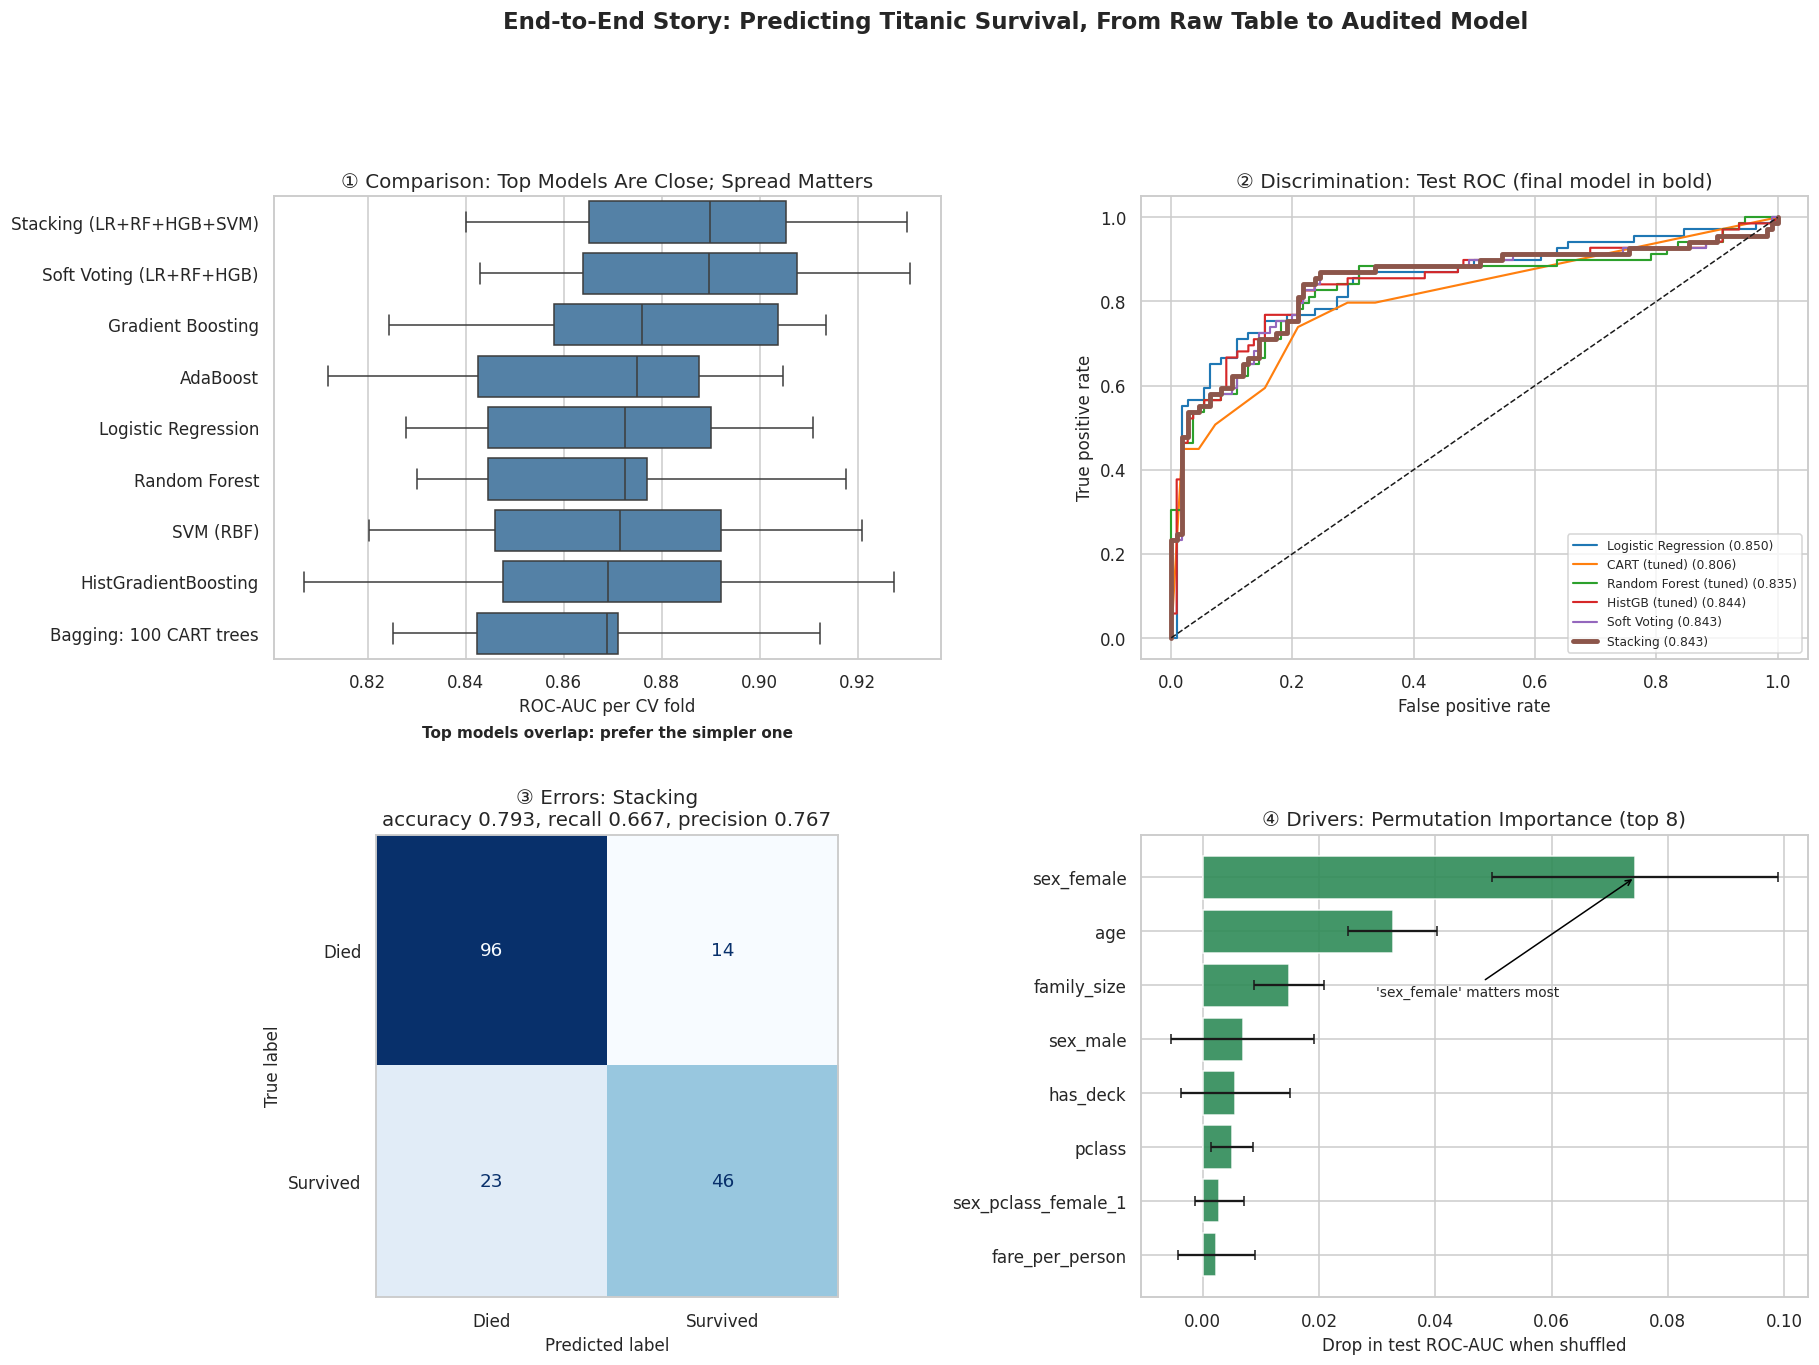

Dashboard saved as workflow_dashboard.png


In [ ]:
fig = plt.figure(figsize=(18, 13))
fig.suptitle("End-to-End Story: Predicting Titanic Survival, From Raw Table to Audited Model", fontsize=15, fontweight="bold", y=1.01)
gs = gridspec.GridSpec(2, 2, hspace=0.38, wspace=0.30)

ax1 = fig.add_subplot(gs[0, 0])
top_models = pd.DataFrame(fold_auc).median().sort_values(ascending=False).head(9).index.tolist()
sns.boxplot(data=pd.DataFrame(fold_auc)[top_models], orient="h", color="steelblue", ax=ax1)
ax1.set_xlabel("ROC-AUC per CV fold"); ax1.set_title("① Comparison: Top Models Are Close; Spread Matters")
ax1.text(0.5, -0.17, "Top models overlap: prefer the simpler one", transform=ax1.transAxes, ha="center",
         fontsize=10, fontweight="bold")

ax2 = fig.add_subplot(gs[0, 1])
for (n, p), color in zip(proba.items(), pal):
    fpr, tpr, _ = roc_curve(y_test, p)
    ax2.plot(fpr, tpr, color=color, linewidth=3.2 if n == final_name else 1.4, label=f"{n} ({roc_auc_score(y_test, p):.3f})")
ax2.plot([0, 1], [0, 1], "k--", linewidth=1)
ax2.set_xlabel("False positive rate"); ax2.set_ylabel("True positive rate"); ax2.set_title("② Discrimination: Test ROC (final model in bold)")
ax2.legend(loc="lower right", fontsize=8)

ax3 = fig.add_subplot(gs[1, 0])
ConfusionMatrixDisplay.from_predictions(y_test, pred_final, display_labels=["Died", "Survived"], cmap="Blues", colorbar=False, ax=ax3, values_format="d")
ax3.grid(False); m_ = test_df.loc[final_name]
ax3.set_title(f"③ Errors: {final_name}\naccuracy {m_['accuracy']:.3f}, recall {m_['recall']:.3f}, precision {m_['precision']:.3f}")

ax4 = fig.add_subplot(gs[1, 1])
t8 = perm_df.tail(8)
ax4.barh(t8["feature"], t8["importance"], xerr=t8["std"], color="seagreen", edgecolor="white", alpha=0.9, capsize=3)
ax4.set_xlabel("Drop in test ROC-AUC when shuffled"); ax4.set_title("④ Drivers: Permutation Importance (top 8)")
lead = t8.iloc[-1]
ax4.annotate(f"'{lead['feature']}' matters most", xy=(lead["importance"], len(t8) - 1), xytext=(lead["importance"] * 0.4, len(t8) - 3.2),
             fontsize=9, arrowprops=dict(arrowstyle="->", color="black"))
plt.tight_layout()
plt.savefig("workflow_dashboard.png", dpi=110, bbox_inches="tight")
plt.show()
print("Dashboard saved as workflow_dashboard.png")

### Exercise 1: Your Turn: Run All 36 Steps on a New Dataset

Load the **penguins** dataset and predict `sex`:

```python
peng = sns.load_dataset("penguins")
```

Repeat the workflow **in the same order, one cell per step**, writing a one-line comment on every decision:

1. **Load and inspect** (Steps 2-3), then **target balance** (Step 4). Which rows can never be used for training (hint: look at the target)?
2. **Leaky or redundant columns and duplicates** (Step 5), **missing-value report** (Step 6).
3. **Stratified split** (Step 7).
4. **Engineer** at least three features, **impute**, check **outliers/skew**, **one-hot encode**, **scale** (Steps 8-12), and assemble matrices (Step 13).
5. **Select features** (Step 14) and fit a **baseline** (Step 15).
6. Compare **at least eight models** including CART, bagging or Random Forest, boosting, voting, and stacking (Steps 16-22), with a Wilcoxon test.
7. **Tune** one model and estimate it with **nested CV** (Step 23).
8. Choose the final model by CV, then run **Steps 25-33** on the test set: metric table, confusion matrix, ROC/PR, calibration, threshold, bootstrap CI and McNemar, learning curve, permutation importance, subgroup accuracy by `species`.
9. Rebuild as a **leak-proof Pipeline**, save it, and score two new penguins (Step 35).
10. Write 4-5 sentences: which preparation choices mattered most, whether any ensemble beat the best single model significantly, how confident you are in the test numbers, and where the model fails.

```python
# Your code here
```

```
# Your answer here
```

---
## Summary: The Workflow at a Glance

| Step | Stage | Purpose | Key tools |
|---|---|---|---|
| 1-3 | **Load and inspect** | Know the data | `read`, `dtypes`, `describe` |
| 4 | **Target** | Balance decides split and metrics | `value_counts` |
| 5 | **Leakage and redundancy** | Remove columns that cheat or repeat | equality checks, `crosstab` |
| 6 | **Missingness** | Size and meaning of gaps | `isna`, survival by missing flag |
| 7 | **Split** | Seal the test set | `train_test_split(stratify=y)` |
| 8 | **Feature engineering** | Expose structure | stateless functions, flags, ratios, interactions |
| 9 | **Imputation** | Fill gaps from train statistics | `fillna`, `SimpleImputer`, `KNNImputer` |
| 10 | **Outliers and skew** | Tame extremes without deleting real data | IQR rule, `log1p` |
| 11 | **Encoding** | Categories to numbers | `OneHotEncoder(handle_unknown="ignore")` |
| 12 | **Scaling** | Comparable ranges | `StandardScaler`, `MinMaxScaler`, `RobustScaler` |
| 13-14 | **Matrices and selection** | Final features | `SelectKBest`, `RFE`, L1 |
| 15-16 | **Baseline and single models** | Floor and first comparison | `DummyClassifier`, `cross_validate` |
| 17 | **CART** | Interpretable trees, pruning | `plot_tree`, `max_depth`, `ccp_alpha` |
| 18-21 | **Ensembles** | Cancel errors | Bagging, Random Forest, boosting, voting, stacking |
| 22 | **Compare and test** | Is the winner real? | Wilcoxon, diversity analysis |
| 23 | **Tuning** | Hyperparameters, honestly | grid, random search, nested CV |
| 24-25 | **Final choice and test metrics** | Select on CV, report on test once | accuracy to MCC, ROC-AUC, PR-AUC, Brier |
| 26-29 | **Errors, curves, calibration, threshold** | Understand the mistakes | confusion matrix, ROC/PR, reliability diagram, cost curve |
| 30-31 | **Uncertainty and diagnosis** | How sure, and would more data help? | bootstrap CI, McNemar, learning curve |
| 32-33 | **Interpretation and audit** | Trust and fairness | permutation importance, partial dependence, subgroups |
| 34-36 | **Deliver** | Model card, leak-proof pipeline, dashboard | `Pipeline`, `joblib` |

---
**The ML workflow in one breath:**  
Load and audit the data, remove leaks, **split first**, engineer features, impute, treat outliers, encode, scale, select features; fit a baseline, compare many models and ensembles with the same CV folds, tune, choose the final model by CV, open the test set **once**, report several metrics with uncertainty, check calibration, threshold, and subgroups, then ship one leak-proof Pipeline.